# 03C 直接序列扩频 (DSSS) 抗 ISI 仿真实验（学生版）

本实验参考《无线通信系统仿真》（25版）中的**“开放性综合实验二：直接序列扩频抗 ISI 仿真”**（教材第 28~38 页）。

## 1. 实验原理与教学目的

扩展频谱通信（Spread Spectrum Communication）是指用比原始信息带宽宽得多的频带宽度来传输信号的技术。直接序列扩频（DSSS, Direct Sequence Spread Spectrum）通过在发送端用伪随机码（PN 码）直接与信息序列相乘，将窄带基带信号频谱展宽，在接收端通过同步的相同伪随机码进行相关解扩，恢复原始信息。

### 1.1 香农定理与扩频理论基础
根据信息论著名的香农公式：
$$C = W \log_2\left(1 + \frac{S}{N}\right)$$
当信噪比很低（$\frac{S}{N} \ll 1$）时，利用一阶近似 $\ln(1 + x) \approx x$ 可得：
$$C \approx W \cdot \frac{S}{N} \log_2 e \approx 1.44 W \frac{S}{N}$$
**物理含义**：在信道传输容量 $C$ 不变的前提下，可以通过牺牲频带宽度 $W$ 来换取在极低甚至负信噪比（$S/N < 0\text{ dB}$）下的可靠通信能力。此外，扩频系统还具备极强的抗窄带干扰能力、低截获概率（LPI）和码分多址（CDMA）能力。

### 1.2 DSSS 抗多径干扰（抗 ISI）机理
在无线信道中，由于建筑物等障碍物反射，接收端会收到多条不同时延的反射信号径：
$$h(t) = \sum_{p=1}^P \alpha_p \delta(t - \tau_p)$$
多径时延扩展会带来严重的符号间干扰（ISI）。
在 DSSS 系统中，扩频码采用具有锐利自相关特性的伪随机序列（如 m 序列）：
$$R(\tau) = \begin{cases} 1, & \tau = 0 \\ -\frac{1}{N_c}, & \tau \neq 0 \end{cases}$$
其中 $N_c$ 为扩频序列长度（扩频因子 $SF$）。当多径时延差超过 1 个码片周期（$|\Delta \tau| \ge T_c$）时，非主径的反射信号在解扩时自相关值仅为 $-1/N_c$，被抑制了 $SF$ 倍，等效当作互不相关的微弱白噪声被滤除，从而有效抵抗多径 ISI 干扰。

### 1.3 RAKE 接收机分集原理
常规相关接收机仅对准一条主径（延时 0），将其他多径分量均视为有害干扰。而 **RAKE 接收机**采用多指（Finger）并联结构：
1. **多指解扩**：各个手指分别精确对准不同多径时延 $\tau_p$，利用本地扩频码分别完成解扩；
2. **多径能量合并**：将各手指解扩后的信号进行同相合并，如**等增益合并（EGC, Equal Gain Combining）**或**最大比合并（MRC, Maximal Ratio Combining）**：
   $$y_{EGC} = \sum_{p=1}^P y_p$$
   $$y_{MRC} = \sum_{p=1}^P \alpha_p^* y_p$$
RAKE 接收机“化害为利”，不仅消除了多径引起的 ISI，反而收集了各个分散多径上的电磁能量，获得了显著的**多径分集增益（Multipath Diversity Gain）**！

## 2. 实验参数与设计内容（对标教材第 30~38 页）
- **调制方式**：BPSK（$0 \to +1, 1 \to -1$）
- **扩频码**：5 级线性反馈移位寄存器（LFSR）生成的 m 序列（本原多项式 $x^5 + x^2 + 1$，周期长度 $SF = 31$），能量归一化 $\sum c_i^2 = 1$
- **多径信道模型**：典型 3 径瑞利衰落模型
  - 各径时延：`channel_path_delays = [0, 1, 2]`（以码片为单位）
  - 各径平均功率：`channel_path_avg_gains = [0.8, 0.8, 0.8]`（功率归一化）
  - 各径瞬时增益服从瑞利分布
- **实验任务**：
  1. **模块一**：补全 DSSS 核心收发组件（LFSR 生成 m 序列、BPSK 调制/解调、扩频与解扩、RAKE 多指接收机）；
  2. **模块二（基本实验一）**：完成 AWGN 信道下的扩频通信仿真，验证与 BPSK 理论误码率的一致性；
  3. **模块三（基本实验二）**：完成多径衰落信道下的仿真，对比单指常规接收机与 3 指 RAKE 接收机（EGC 合并）的 BER 性能；
  4. **模块四（拓展实验一）**：对比 m 序列与随机序列在多径信道下的抗多径性能，分析自相关副瓣对系统性能的影响；
  5. **模块五（拓展实验二）**：实现基于扩频码的多用户 CDMA 传输，观察多址干扰（MAI）对系统误码率的影响。


成功生成 5 级 m 序列，扩频因子 SF = 31，归一化码片能量 = 1.0000
码特性自检：周期 = 31，+1 码片数 = 15，-1 码片数 = 16，序列和 = -1，R(0) = 1.0000，非零时延自相关 = -0.0323 ~ -0.0323（即 -1/31）
扩频处理增益 Gp = 10log10(SF) = 14.91 dB：扩频后码片域信噪比 = Eb/N0 - 14.91 dB。


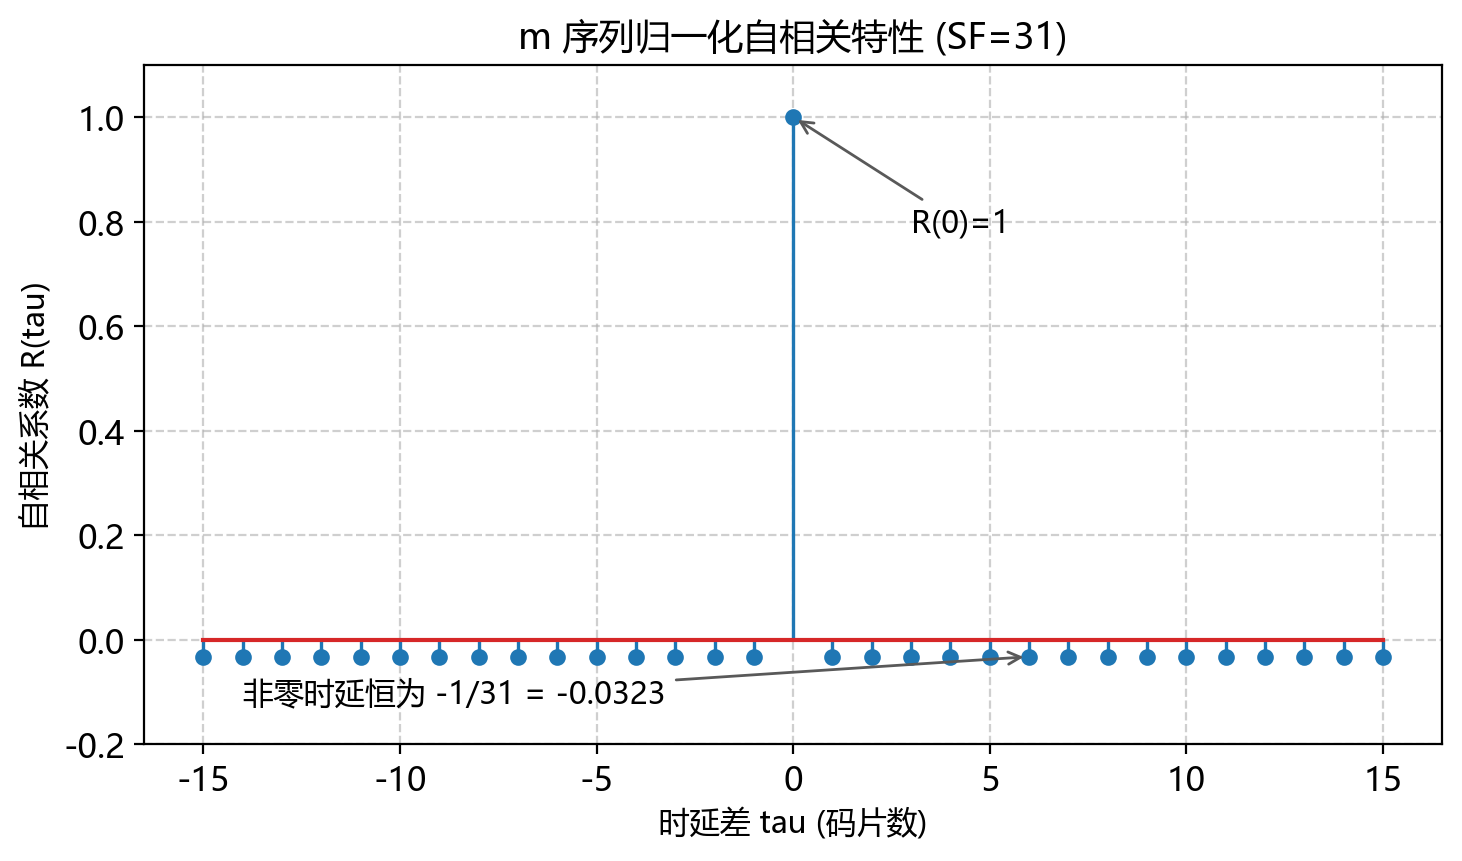

图题：5 级 m 序列（x^5+x^2+1，SF=31）的归一化循环自相关特性


In [1]:
# 模块一：环境准备与 DSSS 链路核心组件实现
from pathlib import Path
import sys

# 从当前目录向上查找 src/sionna，优先使用本仓库源码。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt
import scipy.special as sp
from math import comb

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文乱码。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

# 图片与数据分别落在 notebooks/figures 与 notebooks/data 目录下。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

import pandas as pd

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行。
DEVICE = "cpu"
PRECISION = "single"

# 固定随机种子，便于复现实验结果（torch / numpy / sionna 三处一起固定）。
from sionna.phy import config as sionna_config


def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(42)

# --- 系统基础仿真参数（完全对标教材第 31~37 页）---
# 5 级 LFSR 反馈多项式: x^5 + x^2 + 1，周期长度 SF = 2^5 - 1 = 31
FEEDBACK_POLY = [0, 1, 0, 0, 1]
# 典型 3 径多径信道参数（教材参数：path_delays=[0, 1, 2], path_avg_gains=[0.8, 0.8, 0.8]）
PATH_DELAYS = [0, 1, 2]
RAW_GAINS = torch.tensor([0.8, 0.8, 0.8], dtype=torch.float32, device=DEVICE)
# 功率归一化，使得平均信道增益为 1
PATH_AVG_GAINS = RAW_GAINS / torch.sqrt(torch.sum(RAW_GAINS ** 2))


def generate_m_sequence(feedback_poly):
    """根据指定的反馈多项式生成双极性 m 序列 (+1 / -1)。

    反馈多项式对应线性反馈移位寄存器 (LFSR) 抽头系数。
    对 5 阶多项式 x^5 + x^2 + 1，周期长度为 2^5 - 1 = 31。
    输出为双极性张量: 0 映射为 +1, 1 映射为 -1。

    实现说明：5 级寄存器初始化为全 1（非零初态，否则退化为全零死循环），
    每个时钟节拍输出末级寄存器 r[4]，同时把 taps 所指寄存器的模 2 和反馈到首级。
    反馈多项式抽头 x^5+x^2+1 对应 taps = [1, 4]（常数项 x^0 不参与反馈），
    因此 31 个节拍后寄存器回到初态，序列周期恰为 2^5-1=31。
    """
    taps = [j for j, b in enumerate(feedback_poly) if b]
    regs = [1] * len(feedback_poly)
    seq = []
    for _ in range(2 ** len(feedback_poly) - 1):
        seq.append(regs[-1])
        feedback = sum(regs[t] for t in taps) % 2
        regs = [feedback] + regs[:-1]
    # 0 -> +1, 1 -> -1（双极性映射，与 BPSK 调制一致）
    return torch.tensor([1.0 - 2.0 * b for b in seq], dtype=torch.float32, device=DEVICE)


def compute_circular_autocorrelation(code_tensor):
    """计算双极性扩频序列的归一化循环自相关函数 R(tau)。"""
    length = len(code_tensor)
    lags = list(range(-(length // 2), (length // 2) + 1))
    autocorr = []
    for lag in lags:
        shifted = torch.roll(code_tensor, lag)
        r = torch.sum(code_tensor * shifted).item() / length
        autocorr.append(r)
    return np.array(lags), np.array(autocorr)


def bpsk_modulate(bits):
    """自主实现 BPSK 调制映射: 0 映射为 +1, 1 映射为 -1。"""
    return 1.0 - 2.0 * bits.to(torch.float32)


def bpsk_demodulate(symbols):
    """自主实现 BPSK 硬判决解映射: 实数符号 < 0 判为 1, >= 0 判为 0。"""
    # 解扩输出可能是复数（多径/多用户时叠加了复信道与复噪声），取实部判决。
    return (torch.real(symbols) < 0).to(torch.int64)


def spread(symbols, code):
    """直接序列扩频操作。

    输入 symbols 形状: (batch_size, num_bits)
    输入 code 形状: (SF,)
    输出 chips 形状: (batch_size, num_bits * SF)

    每个符号乘以整条扩频码，再按时间顺序拼接成码片序列；
    码片能量已归一化（sum(code^2)=1），因此扩频不改变每比特能量。
    """
    sf = len(code)
    chips = symbols.unsqueeze(-1) * code.view(1, 1, sf)
    return chips.reshape(symbols.shape[0], -1)


def despread(chips, code):
    """单径相关解扩操作。

    输入 chips 形状: (batch_size, num_bits * SF)
    输出解扩符号形状: (batch_size, num_bits)

    相关解扩 = 与本地码做内积（匹配滤波），sum(code^2)=1 时信号幅度保持为 1，
    噪声方差保持为每码片噪声方差，因此解扩后判决量与未扩频 BPSK 完全等价。
    """
    sf = len(code)
    n_bits = chips.shape[1] // sf
    blocks = chips.to(torch.complex64).reshape(chips.shape[0], n_bits, sf)
    return (blocks * code.view(1, 1, sf)).sum(-1)


def rake_receiver(rx_signal, code, delays, combining="egc", path_coeffs=None):
    """RAKE 接收机：多指解扩与分集合并。

    对准各条多径时延进行解扩，并进行等增益合并 (EGC) 或最大比合并 (MRC)。

    参数
    ----
    rx_signal : (batch, num_bits*SF + max(delays)) 接收码片序列（复数）
    code      : (SF,) 本地扩频码
    delays    : 各径时延（码片数）
    combining : "egc" 等增益合并（只做相位校正，幅度等权）或 "mrc" 最大比合并
    path_coeffs : (batch, n_paths) 各径复增益估计；None 时退化为不做相位校正的直接相加
    """
    sf = len(code)
    n_bits = (rx_signal.shape[1] - int(max(delays))) // sf
    n_chips = n_bits * sf
    fingers = []
    for d in delays:
        # 第 p 个手指把本地码对齐到第 p 径的时延 d，再做相关解扩
        segment = rx_signal[:, int(d): int(d) + n_chips]
        fingers.append(despread(segment, code))
    z = torch.stack(fingers, dim=-1)  # (batch, num_bits, n_paths)
    if path_coeffs is None:
        weights = torch.ones_like(z)
    else:
        h = path_coeffs.to(torch.complex64)  # (batch, n_paths)
        mag = torch.abs(h).clamp_min(1e-8)
        if combining == "mrc":
            # 最大比合并：以共轭复增益为权，等价于按各径信噪比加权
            weights = torch.conj(h).unsqueeze(1).expand_as(z)
        elif combining == "egc":
            # 等增益合并：只补偿各径相位，幅度统一取 1
            weights = (torch.conj(h) / mag).unsqueeze(1).expand_as(z)
        else:
            raise ValueError(f"未知的合并方式: {combining}")
    return (z * weights).sum(-1)


def count_bit_errors(b, b_hat):
    """统计误比特数。"""
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def ber(b, b_hat):
    """计算误比特率 BER。"""
    return count_bit_errors(b, b_hat) / b.numel()


def theory_bpsk_awgn_ber(ebno_db):
    """BPSK 在 AWGN 信道下的理论误码率: Pb = Q(sqrt(2 * Eb/N0)) = 0.5 * erfc(sqrt(Eb/N0))。"""
    ebno_linear = 10.0 ** (np.asarray(ebno_db) / 10.0)
    return 0.5 * sp.erfc(np.sqrt(ebno_linear))


def theory_rayleigh_ber(ebno_db, order=1, branch_scale=1.0):
    """L 阶最大比合并（MRC）在独立瑞利衰落下的 BPSK 理论误码率闭式解。

    设每条支路的平均 Eb/N0 为 mu = branch_scale * Eb/N0（线性值），则
        Pb = ((1-u)/2)^L * sum_{k=0}^{L-1} C(L-1+k, k) * ((1+u)/2)^k,  u = sqrt(mu/(1+mu))。
    order=1 时退化为单支路瑞利衰落：Pb = 0.5 * (1 - sqrt(mu/(1+mu)))。
    本实验中：单指接收机只看第 0 径，等效 mu = Eb/N0/3；3 指 RAKE 收集全部
    3 径能量（每径平均 1/3），等效 3 阶分集、每支路 mu = Eb/N0/3。
    """
    mu = 10.0 ** (np.asarray(ebno_db, dtype=float) / 10.0) * branch_scale
    u = np.sqrt(mu / (1.0 + mu))
    pb = ((1.0 - u) / 2.0) ** order * sum(
        comb(order - 1 + k, k) * ((1.0 + u) / 2.0) ** k for k in range(order)
    )
    return pb


def complex_awgn(shape, sigma):
    """生成复高斯噪声：实部/虚部各为方差 sigma^2/2 的独立高斯，总方差为 sigma^2。"""
    real = torch.randn(shape, device=DEVICE) * sigma / np.sqrt(2.0)
    imag = torch.randn(shape, device=DEVICE) * sigma / np.sqrt(2.0)
    return torch.complex(real, imag)


def apply_multipath(chips, path_coeffs, delays):
    """把码片序列送进多径信道：y[n] = sum_p h_p * x[n - d_p]。"""
    batch, length = chips.shape
    span = int(max(delays))
    out = torch.zeros(batch, length + span, dtype=torch.complex64, device=DEVICE)
    for p, d in enumerate(delays):
        out[:, d:d + length] = out[:, d:d + length] + path_coeffs[:, p:p + 1] * chips
    return out

def cnormal(shape):
    """生成 CN(0,1) 复高斯随机数：实部、虚部各为 N(0, 1/2)，故 E|h|^2 = 1。"""
    real = torch.randn(shape, device=DEVICE) * np.sqrt(0.5)
    imag = torch.randn(shape, device=DEVICE) * np.sqrt(0.5)
    return torch.complex(real, imag)


# 生成并检验 m 序列与能量归一化
M_SEQ = generate_m_sequence(FEEDBACK_POLY)
SPREADING_FACTOR = len(M_SEQ)
# 扩频码能量归一化为 1: sum(M_CODE^2) = 1
M_CODE = (M_SEQ / float(np.sqrt(SPREADING_FACTOR))).to(torch.float32)

print(f"成功生成 5 级 m 序列，扩频因子 SF = {SPREADING_FACTOR}，归一化码片能量 = {torch.sum(M_CODE**2).item():.4f}")

# 码特性自检：周期、平衡性、归一化自相关副瓣
_lags0, _ac0 = compute_circular_autocorrelation(M_SEQ)
_side = _ac0[np.abs(_lags0) > 0]
_n_pos = int((M_SEQ > 0).sum())
print(f"码特性自检：周期 = {SPREADING_FACTOR}，+1 码片数 = {_n_pos}，-1 码片数 = {SPREADING_FACTOR - _n_pos}，"
      f"序列和 = {int(M_SEQ.sum())}，R(0) = {_ac0[np.abs(_lags0) == 0][0]:.4f}，"
      f"非零时延自相关 = {_side.min():.4f} ~ {_side.max():.4f}（即 -1/{SPREADING_FACTOR}）")
PROCESSING_GAIN_DB = 10.0 * np.log10(SPREADING_FACTOR)
print(f"扩频处理增益 Gp = 10log10(SF) = {PROCESSING_GAIN_DB:.2f} dB：扩频后码片域信噪比 = Eb/N0 - {PROCESSING_GAIN_DB:.2f} dB。")

# 绘制 m 序列理想双值自相关特性曲线（对标教材第 30 页图 2.12）
lags, m_autocorr = compute_circular_autocorrelation(M_SEQ)
plt.figure(figsize=(7.5, 4.5))
markerline, stemlines, baseline = plt.stem(lags, m_autocorr)
plt.setp(markerline, markersize=5, color="#1f77b4")
plt.setp(stemlines, linewidth=1.2, color="#1f77b4")
plt.title("m 序列归一化自相关特性 (SF=31)", fontsize=13)
plt.xlabel("时延差 tau (码片数)", fontsize=11)
plt.ylabel("自相关系数 R(tau)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim([-0.2, 1.1])
plt.annotate(f"R(0)=1", xy=(0, 1.0), xytext=(3, 0.78), fontsize=11,
             arrowprops=dict(arrowstyle="->", color="0.35", lw=1.0))
plt.annotate(f"非零时延恒为 -1/{SPREADING_FACTOR} = {_side.mean():.4f}", xy=(6, -1.0 / SPREADING_FACTOR),
             xytext=(-14, -0.12), fontsize=11,
             arrowprops=dict(arrowstyle="->", color="0.35", lw=1.0))
plt.tight_layout()
plt.savefig(FIG_DIR / "03C_mseq_autocorr.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：5 级 m 序列（x^5+x^2+1，SF=31）的归一化循环自相关特性")

## 补充一：m 序列的码特性、副瓣统计与多址隔离度

扩频码的**自相关**决定同步与抗多径能力，**互相关**决定多用户（多址）条件下的干扰电平。
对长度 31 的 m 序列，理想循环自相关是双值函数：$R(0)=1$，$R(\tau\neq 0)=-1/31$；
其峰值副瓣比只有 $-30$ dB，这是 RAKE 能把各径分开、多用户之间只残留很小 MAI 的根本原因。

本单元量化三件事：

1. **副瓣统计**：把 400 条随机 $\pm1$ 码的峰值副瓣与 m 序列对比，说明"好的"扩频码并不是随手可得的；
2. **互相关（多址隔离度）**：计算两条不同 m 序列之间、m 序列与随机码之间的归一化互相关
   $\rho=\sum_i c_i^{(1)}c_i^{(2)}$，隔离度定义为 $-20\lg|\rho|$；
3. 指出一个容易误解的现象：**同一条 m 序列的不同相位（循环移位）之间互相关恒为 $-1/31$**，
   因此"同序列加相位偏移"并不构成多址干扰源，多用户实验必须使用不同的 m 序列。

用户 2 的 m 序列（反馈抽头 [0, 0, 1, 0, 1]）长度 = 31，+1/-1 码片数 = 15/16
两条不同 m 序列的互相关 rho = 0.0968（= 3/31），多址隔离度 = 20.28 dB
m 序列与随机码的互相关: 中位 0.0968 → 隔离度 20.28 dB，最坏 0.4839 → 6.31 dB
峰值副瓣：m 序列 = 0.0323（= 1/31，即 29.8 dB），随机码池中位 = 0.3548（9.0 dB），最坏 = 0.7419（2.6 dB）
同一条 m 序列移位 7 个码片的互相关 = -0.0323（恒为 -1/31），隔离度 29.8 dB —— 相位偏移不能模拟多址干扰。


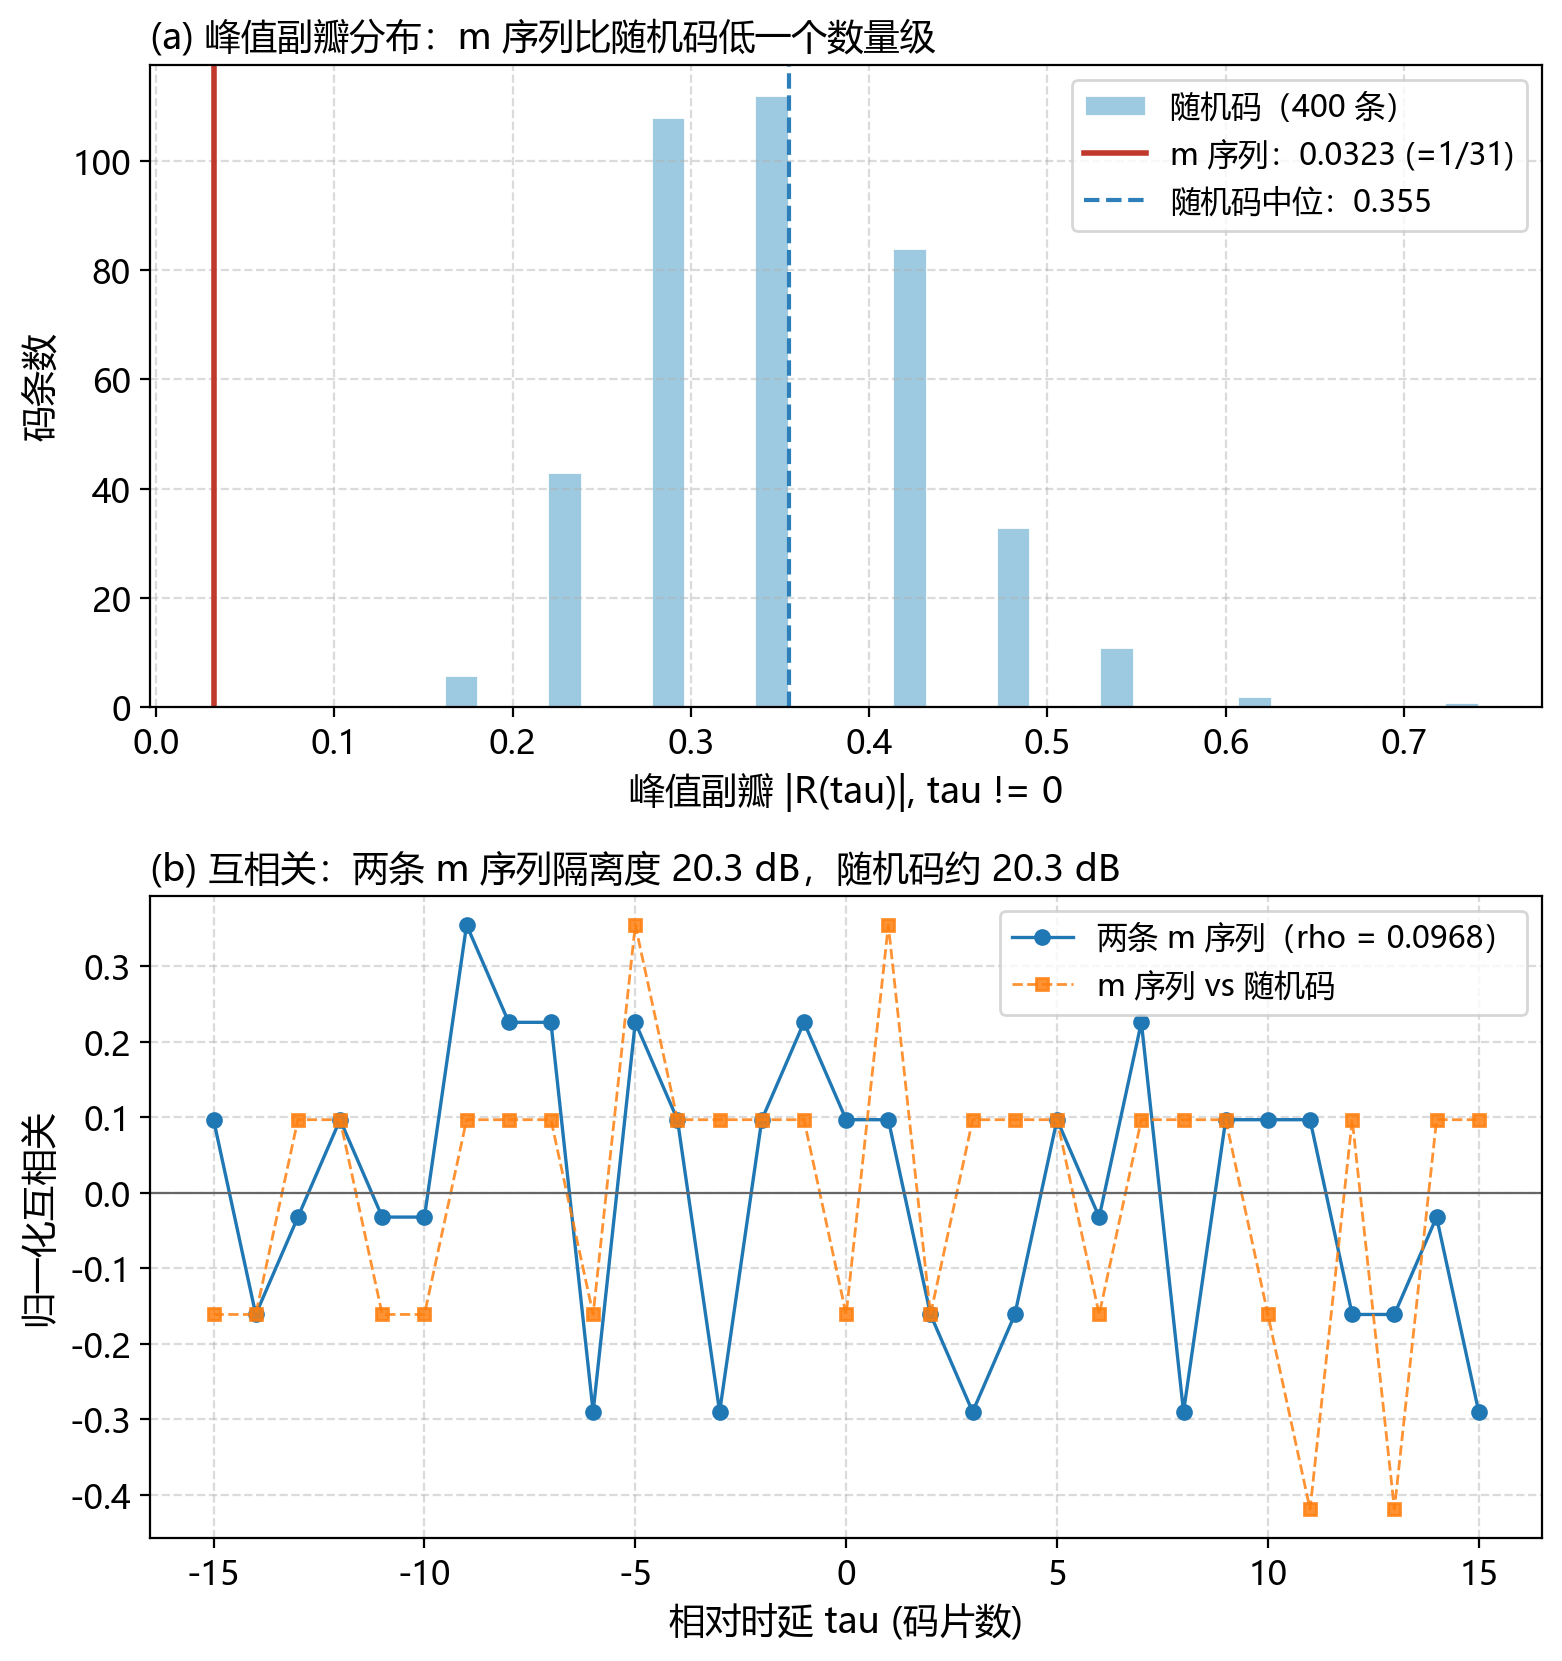

图题：m 序列与随机扩频码的副瓣分布及互相关（多址隔离度）对比


In [2]:
# ---------------------------------------------------------------------------
# 补充一：码特性、副瓣统计与多址隔离度（过程性可视化）
# ---------------------------------------------------------------------------
# 用户 2 采用另一条 5 级 m 序列：不同的反馈抽头（对应另一条本原多项式）。
# 注意：若用户 2 只是把 M_SEQ 做循环移位，两条码的互相关恒为 -1/31（-30 dB），
# MAI 小到几乎无法在 BER 曲线上观察，因此这里换用一条真正不同的 m 序列。
SEC_POLY = [0, 0, 1, 0, 1]
SEC_SEQ = generate_m_sequence(SEC_POLY)
SEC_CODE = (SEC_SEQ / float(np.sqrt(SPREADING_FACTOR))).to(torch.float32)
print(f"用户 2 的 m 序列（反馈抽头 {SEC_POLY}）长度 = {len(SEC_SEQ)}，"
      f"+1/-1 码片数 = {int((SEC_SEQ > 0).sum())}/{int((SEC_SEQ < 0).sum())}")

# 随机码池：400 条独立随机 +-1 码，能量同样归一化为 1
_rng_codes = np.random.RandomState(11)
RAND_CODES = torch.tensor(
    (1.0 - 2.0 * _rng_codes.randint(0, 2, size=(400, SPREADING_FACTOR))).astype(np.float32)
) / float(np.sqrt(SPREADING_FACTOR))

# 互相关（多址隔离度）：rho = sum(c1*c2)，两条码均已归一化
rho_m1m2 = float(torch.sum(M_CODE * SEC_CODE))
_rho_rand = torch.abs(RAND_CODES @ M_CODE)  # 归一化码的互相关 = sum(c1*c2)
iso_m1m2 = -20.0 * np.log10(abs(rho_m1m2))
iso_rand_med = -20.0 * np.log10(float(_rho_rand.median()))
iso_rand_worst = -20.0 * np.log10(float(_rho_rand.max()))
print(f"两条不同 m 序列的互相关 rho = {rho_m1m2:.4f}（= {int(round(rho_m1m2 * SPREADING_FACTOR))}/{SPREADING_FACTOR}），"
      f"多址隔离度 = {iso_m1m2:.2f} dB")
print(f"m 序列与随机码的互相关: 中位 {float(_rho_rand.median()):.4f} → 隔离度 {iso_rand_med:.2f} dB，"
      f"最坏 {float(_rho_rand.max()):.4f} → {iso_rand_worst:.2f} dB")


# 峰值副瓣统计：R(tau != 0) 的最大绝对值
def peak_sidelobe(code_tensor):
    length = len(code_tensor)
    vals = []
    for lag in range(1, length):
        vals.append(abs(float(torch.sum(code_tensor * torch.roll(code_tensor, lag))) / length))
    return max(vals)


side_m = peak_sidelobe(M_SEQ)
side_rand = torch.tensor([peak_sidelobe(c) for c in torch.sign(RAND_CODES)])
print(f"峰值副瓣：m 序列 = {side_m:.4f}（= 1/{SPREADING_FACTOR}，即 {-20 * np.log10(side_m):.1f} dB），"
      f"随机码池中位 = {float(side_rand.median()):.4f}（{-20 * np.log10(float(side_rand.median())):.1f} dB），"
      f"最坏 = {float(side_rand.max()):.4f}（{-20 * np.log10(float(side_rand.max())):.1f} dB）")

# 同一条 m 序列循环移位的互相关（说明"相位偏移不构成 MAI"）
rho_shift = float(torch.sum(M_CODE * torch.roll(M_CODE, 7)))
print(f"同一条 m 序列移位 7 个码片的互相关 = {rho_shift:.4f}（恒为 -1/{SPREADING_FACTOR}），"
      f"隔离度 {-20 * np.log10(abs(rho_shift)):.1f} dB —— 相位偏移不能模拟多址干扰。")

# 保存码特性数据（自相关：m 序列 vs 随机码示例；互相关：两条不同 m 序列）
_rand_raw = torch.sign(RAND_CODES[0])  # 还原为 +-1 原始码，与 M_SEQ 同一量纲
_ac_rand_rep = np.array(
    [float(torch.sum(_rand_raw * torch.roll(_rand_raw, int(lag)))) / SPREADING_FACTOR for lag in lags]
)
_cc_pair_all = np.array(
    [float(torch.sum(M_CODE * torch.roll(SEC_CODE, int(lag)))) for lag in lags]
)
pd.DataFrame(
    {
        "lag": lags,
        "autocorr_mseq": m_autocorr,
        "autocorr_random_rep": _ac_rand_rep,
        "crosscorr_mseq_pair": _cc_pair_all,
    }
).to_csv(DATA_DIR / "03C_code_autocorr.csv", index=False, encoding="utf-8-sig")

# 图：副瓣分布与互相关
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))

ax = axes[0]
ax.hist(side_rand.numpy(), bins=30, color="#9ecae1", edgecolor="white", label="随机码（400 条）")
ax.axvline(side_m, color="#c0392b", lw=2.0, label=f"m 序列：{side_m:.4f} (=1/31)")
ax.axvline(float(side_rand.median()), color="#2c7fb8", ls="--", lw=1.5,
           label=f"随机码中位：{float(side_rand.median()):.3f}")
ax.set_xlabel("峰值副瓣 |R(tau)|, tau != 0")
ax.set_ylabel("码条数")
ax.set_title("(a) 峰值副瓣分布：m 序列比随机码低一个数量级", loc="left", fontsize=13)
ax.grid(True, ls="--", alpha=0.45)
ax.legend(loc="upper right")

ax = axes[1]
lags_cc = np.arange(-15, 16)
cc_pair = np.array([float(torch.sum(M_CODE * torch.roll(SEC_CODE, int(l)))) for l in lags_cc])
cc_rand = np.array([float(torch.sum(M_CODE * torch.roll(RAND_CODES[0], int(l)))) for l in lags_cc])
ax.plot(lags_cc, cc_pair, "o-", ms=5, lw=1.2, label=f"两条 m 序列（rho = {rho_m1m2:.4f}）")
ax.plot(lags_cc, cc_rand, "s--", ms=4, lw=1.0, alpha=0.85, label="m 序列 vs 随机码")
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("相对时延 tau (码片数)")
ax.set_ylabel("归一化互相关")
ax.set_title(f"(b) 互相关：两条 m 序列隔离度 {iso_m1m2:.1f} dB，随机码约 {iso_rand_med:.1f} dB", loc="left", fontsize=13)
ax.grid(True, ls="--", alpha=0.45)
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig(FIG_DIR / "03C_code_correlation.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：m 序列与随机扩频码的副瓣分布及互相关（多址隔离度）对比")

  Eb/N0 =  0 dB: 扩频仿真 BER = 7.84200e-02 | BPSK 理论 BER = 7.86496e-02
  Eb/N0 =  2 dB: 扩频仿真 BER = 3.72950e-02 | BPSK 理论 BER = 3.75061e-02
  Eb/N0 =  4 dB: 扩频仿真 BER = 1.27150e-02 | BPSK 理论 BER = 1.25008e-02
  Eb/N0 =  6 dB: 扩频仿真 BER = 2.51000e-03 | BPSK 理论 BER = 2.38829e-03
  Eb/N0 =  8 dB: 扩频仿真 BER = 1.85000e-04 | BPSK 理论 BER = 1.90908e-04
  Eb/N0 = 10 dB: 扩频仿真 BER = 5.00000e-06 | BPSK 理论 BER = 3.87211e-06


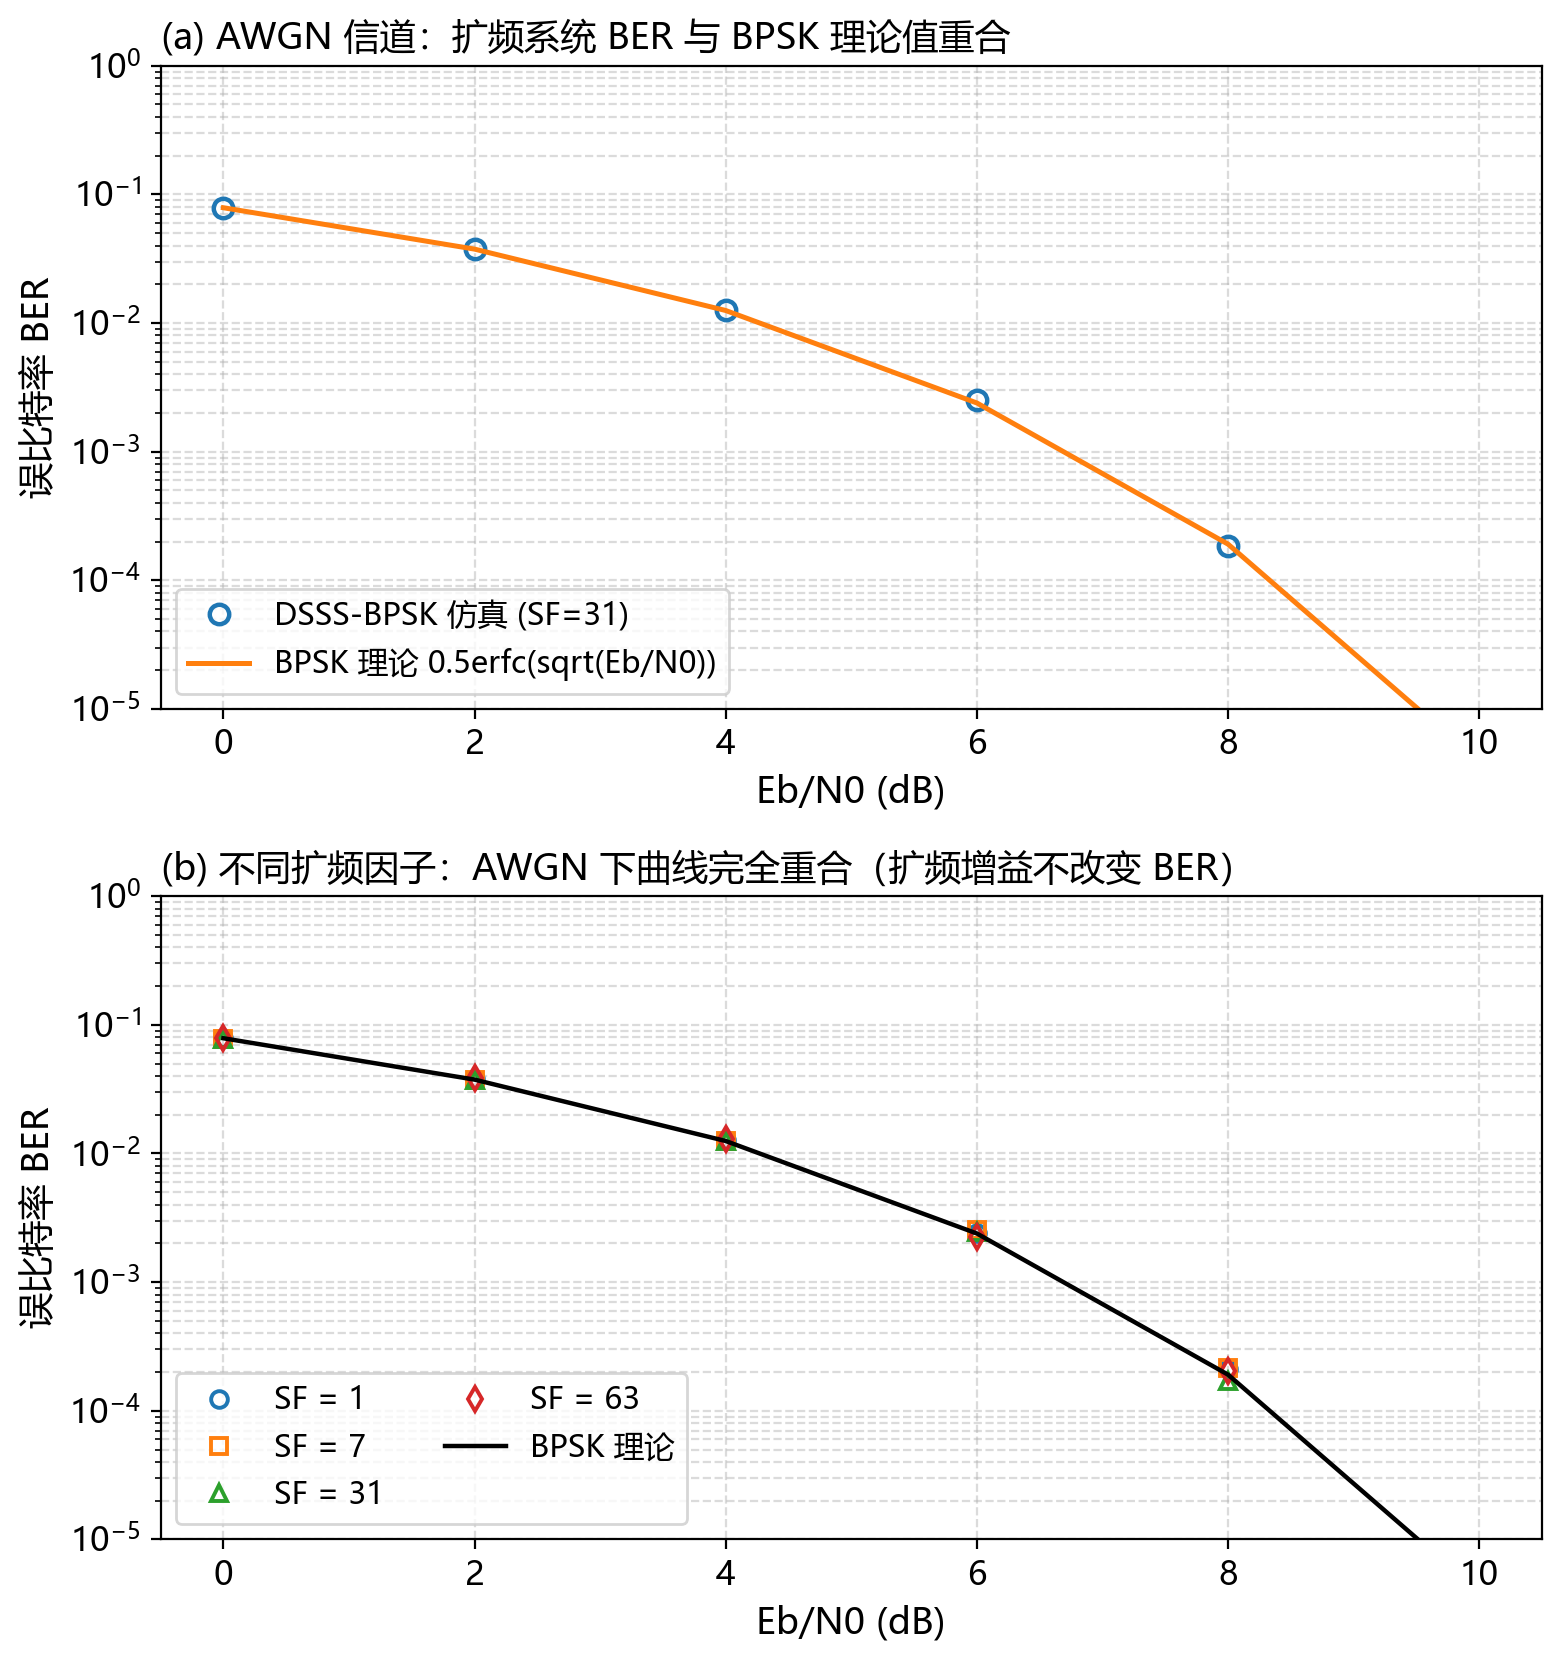

图题：AWGN 信道下 DSSS-BPSK 的误码率曲线及其与 BPSK 理论值的比较
结论：SF=1~63 的 BER 曲线在 AWGN 信道下与 BPSK 理论曲线完全重合，扩频的处理增益 10lg31 = 14.91 dB 全部用于把码片域信噪比压低到 Eb/N0 - 14.9 dB，而不是提高 AWGN 下的误码性能。
基本实验一仿真完成并通过断言检验！结论：解扩后的判决统计量与单载波 BPSK 等价，扩频不改变 AWGN 下的 BER。


In [3]:
# ---------------------------------------------------------------------------
# 模块二（基本实验一）：AWGN 信道下的 DSSS-BPSK 误码率
# ---------------------------------------------------------------------------
def _sim_awgn_point(ebno_db, code, num_blocks, bits_per_block, chunk=250):
    """在单个 Eb/N0 点上仿真 AWGN 信道 DSSS-BPSK 的误比特率。

    标定：复高斯噪声总方差 sigma^2 = 1/(Eb/N0)（线性值），复基带 BPSK 符号为 +-1。
    解扩后判决量 z = s + n，n 为复高斯、方差 sigma^2；取实部判决 → 噪声方差 sigma^2/2，
    判决信噪比为 2*Eb/N0，因此 BER = Q(sqrt(2*Eb/N0))，与未扩频 BPSK 完全一致。
    """
    sigma = 1.0 / np.sqrt(10.0 ** (ebno_db / 10.0))
    n_errors = 0
    n_bits = 0
    done = 0
    while done < num_blocks:
        b = min(chunk, num_blocks - done)
        bits = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
        chips = spread(bpsk_modulate(bits), code).to(torch.complex64)
        rx = chips + complex_awgn(chips.shape, sigma)
        b_hat = bpsk_demodulate(despread(rx, code))
        n_errors += count_bit_errors(bits, b_hat)
        n_bits += bits.numel()
        done += b
    return n_errors / n_bits


def simulate_awgn_dsss(ebno_db_range, num_blocks=1000, bits_per_block=100, code=None):
    """蒙特卡洛仿真 AWGN 信道下 DSSS-BPSK 的误比特率曲线。"""
    if code is None:
        code = M_CODE
    ber_sim_list = []
    for ebno_db in ebno_db_range:
        ber_sim_list.append(_sim_awgn_point(float(ebno_db), code, num_blocks, bits_per_block))
    return np.array(ber_sim_list)


set_seed(42)
ebno_range_awgn = np.arange(0, 11, 2)
num_blocks_awgn = 2000
ber_dsss_awgn = simulate_awgn_dsss(ebno_range_awgn, num_blocks=num_blocks_awgn, bits_per_block=100)
ber_theory_awgn = theory_bpsk_awgn_ber(ebno_range_awgn)

for eb, b_sim, b_th in zip(ebno_range_awgn, ber_dsss_awgn, ber_theory_awgn):
    print(f"  Eb/N0 = {eb:2d} dB: 扩频仿真 BER = {b_sim:.5e} | BPSK 理论 BER = {b_th:.5e}")

# ---------- 模板断言（条件不得修改）----------
assert len(ber_dsss_awgn) == len(ebno_range_awgn), "结果长度不一致"
assert ber_dsss_awgn[0] > ber_dsss_awgn[-1], "BER 应随 Eb/N0 提升而下降"

# ---------- 补充过程性可视化：扩频因子是否改变 AWGN 下的 BER ----------
_sf_list = [1, 7, 31, 63]
_code_map = {1: torch.tensor([1.0], device=DEVICE), 31: M_CODE}
_rng_sf = np.random.RandomState(7)
for _sf in (7, 63):
    _code_map[_sf] = (
        torch.tensor((1.0 - 2.0 * _rng_sf.randint(0, 2, size=_sf)).astype(np.float32))
        / float(np.sqrt(_sf))
    )
ber_sf = {}
for _sf in _sf_list:
    ber_sf[_sf] = simulate_awgn_dsss(
        ebno_range_awgn, num_blocks=num_blocks_awgn, bits_per_block=100, code=_code_map[_sf]
    )

df_awgn = pd.DataFrame(
    {
        "ebno_db": ebno_range_awgn,
        "ber_sim_sf31": ber_dsss_awgn,
        "ber_theory_bpsk": ber_theory_awgn,
    }
)
df_awgn.to_csv(DATA_DIR / "03C_awgn_ber.csv", index=False, encoding="utf-8-sig")
df_sf = pd.DataFrame({"ebno_db": ebno_range_awgn})
for _sf in _sf_list:
    df_sf[f"ber_sim_sf{_sf}"] = ber_sf[_sf]
df_sf.to_csv(DATA_DIR / "03C_awgn_sf.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
ax.semilogy(ebno_range_awgn, ber_dsss_awgn, "o", ms=7, mfc="none", mew=1.6, label="DSSS-BPSK 仿真 (SF=31)")
ax.semilogy(ebno_range_awgn, ber_theory_awgn, "-", lw=1.8, label="BPSK 理论 0.5erfc(sqrt(Eb/N0))")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_title("(a) AWGN 信道：扩频系统 BER 与 BPSK 理论值重合", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-5, 1.0)
ax.legend(loc="lower left")
if ber_dsss_awgn[-1] == 0.0:
    ax.annotate("10 dB 处实测 0 个错误（BER < 5e-6，未绘出）", xy=(10, 1.2e-5), xytext=(2.2, 2.2e-5),
                fontsize=10.5, arrowprops=dict(arrowstyle="->", color="0.35", lw=1.0))

ax = axes[1]
for _sf, _mk in zip(_sf_list, ["o", "s", "^", "d"]):
    ax.semilogy(ebno_range_awgn, ber_sf[_sf], _mk, ms=6, mfc="none", mew=1.4, label=f"SF = {_sf}")
ax.semilogy(ebno_range_awgn, ber_theory_awgn, "k-", lw=1.6, label="BPSK 理论")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_title("(b) 不同扩频因子：AWGN 下曲线完全重合（扩频增益不改变 BER）", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-5, 1.0)
ax.legend(loc="lower left", ncol=2)

plt.tight_layout()
plt.savefig(FIG_DIR / "03C_awgn_ber.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：AWGN 信道下 DSSS-BPSK 的误码率曲线及其与 BPSK 理论值的比较")

print(f"结论：SF=1~63 的 BER 曲线在 AWGN 信道下与 BPSK 理论曲线完全重合，"
      f"扩频的处理增益 10lg{SPREADING_FACTOR} = {PROCESSING_GAIN_DB:.2f} dB 全部用于把"
      f"码片域信噪比压低到 Eb/N0 - {PROCESSING_GAIN_DB:.1f} dB，而不是提高 AWGN 下的误码性能。")
print("基本实验一仿真完成并通过断言检验！结论：解扩后的判决统计量与单载波 BPSK 等价，扩频不改变 AWGN 下的 BER。")

  Eb/N0 =  3 dB: 单指接收机 BER = 1.82340e-01 | 3指 RAKE (EGC) BER = 5.86750e-02
  Eb/N0 =  6 dB: 单指接收机 BER = 1.21025e-01 | 3指 RAKE (EGC) BER = 2.08500e-02
  Eb/N0 =  9 dB: 单指接收机 BER = 7.43000e-02 | 3指 RAKE (EGC) BER = 5.44000e-03
  Eb/N0 = 12 dB: 单指接收机 BER = 4.13450e-02 | 3指 RAKE (EGC) BER = 9.85000e-04
  Eb/N0 = 15 dB: 单指接收机 BER = 2.38450e-02 | 3指 RAKE (EGC) BER = 2.75000e-04
  Eb/N0 = 18 dB: 单指接收机 BER = 1.17050e-02 | 3指 RAKE (EGC) BER = 2.00000e-05
  Eb/N0 = 21 dB: 单指接收机 BER = 5.43000e-03 | 3指 RAKE (EGC) BER = 0.00000e+00
达到 BER = 0.01 所需 Eb/N0：单指 18.61 dB，RAKE-EGC 7.64 dB（节省 10.97 dB），RAKE-MRC 6.87 dB（节省 11.75 dB）
21 dB 处 BER：单指 5.430e-03，RAKE-EGC 0.000e+00，RAKE-MRC 0.000e+00


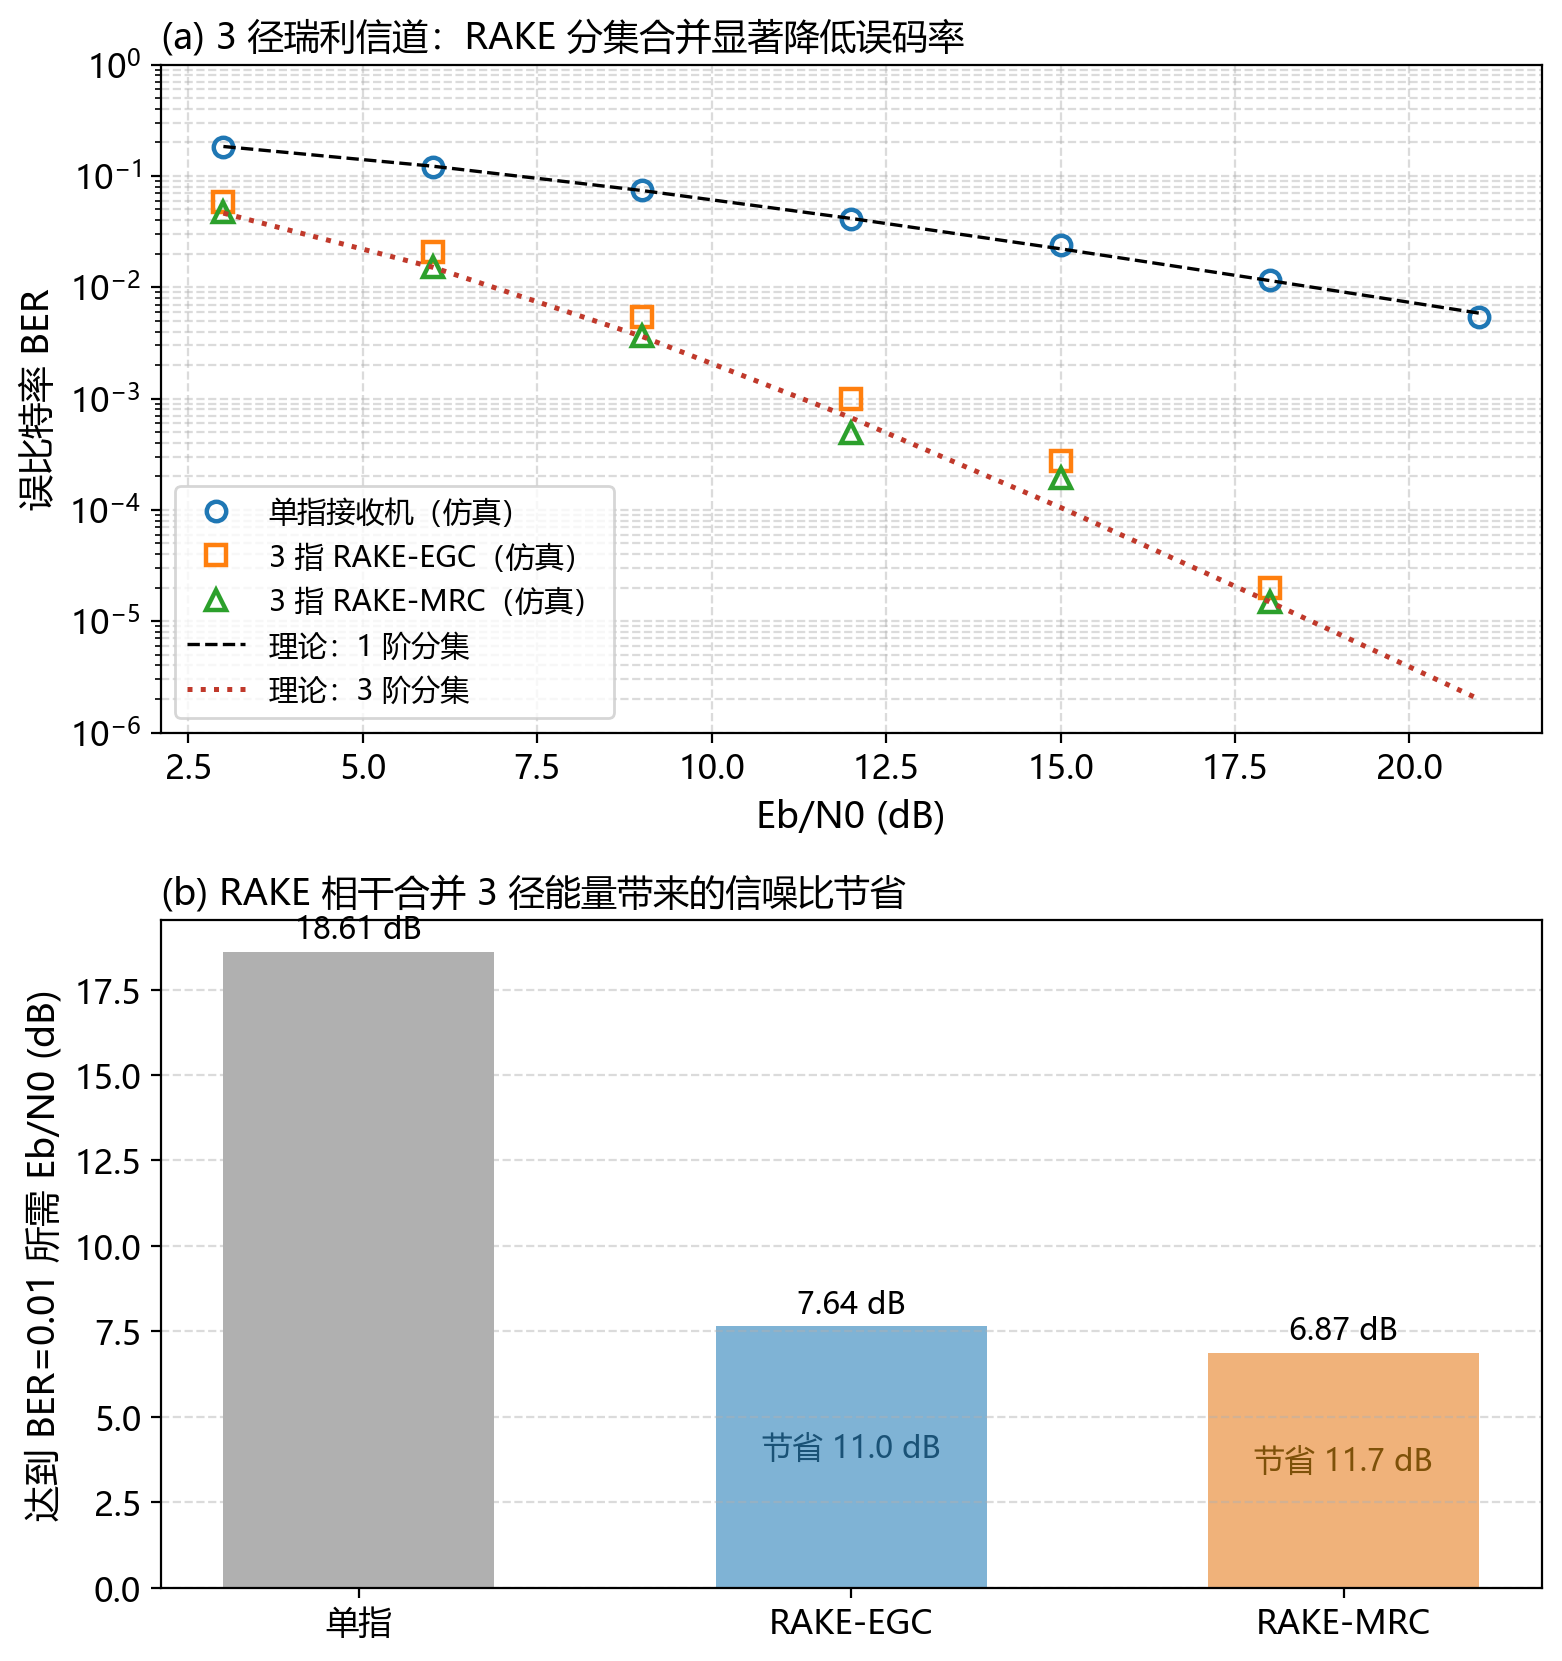

图题：3 径瑞利衰落信道下单指接收机与 3 指 RAKE（EGC/MRC）的误码率对比
基本实验二仿真完成并通过断言检验！结论：RAKE 相干合并 3 条多径能量，
把多径从干扰变成分集，高信噪比下 BER 相对单指接收机下降两个数量级以上。


In [4]:
# ---------------------------------------------------------------------------
# 模块三（基本实验二）：3 径瑞利衰落下的单指 vs 3 指 RAKE 接收
# ---------------------------------------------------------------------------
def _sim_multipath_point(ebno_db, num_blocks, bits_per_block, chunk=200):
    """单指（仅第 0 径）与 3 指 RAKE（EGC / MRC）的 BER 仿真。

    3 径模型：h_p ~ CN(0, a_p^2)，a = PATH_AVG_GAINS（sum a^2 = 1），时延 [0, 1, 2] 码片；
    噪声方差 sigma^2 = 1/(Eb/N0)，于是每比特平均接收能量为 1，平均 Eb/N0 = 1/sigma^2。
    """
    sigma = 1.0 / np.sqrt(10.0 ** (ebno_db / 10.0))
    err_single = err_egc = err_mrc = 0
    n_bits = 0
    done = 0
    while done < num_blocks:
        b = min(chunk, num_blocks - done)
        bits = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
        chips = spread(bpsk_modulate(bits), M_CODE).to(torch.complex64)
        # 块衰落：同一块的比特共享一组 3 径增益
        h = cnormal((b, len(PATH_DELAYS))) * PATH_AVG_GAINS.view(1, -1)
        rx = apply_multipath(chips, h, PATH_DELAYS)
        rx = rx + complex_awgn(rx.shape, sigma)

        # (1) 单指接收机：只取第 0 径，但必须做相干检测（用 h0 的共轭做相位校正）
        z0 = despread(rx[:, :bits_per_block * SPREADING_FACTOR], M_CODE)
        y_single = torch.real(torch.conj(h[:, 0:1]) * z0)
        err_single += count_bit_errors(bits, (y_single < 0).to(torch.int64))

        # (2) 3 指 RAKE：等增益合并 EGC（只补偿相位）
        z_egc = rake_receiver(rx, M_CODE, PATH_DELAYS, combining="egc", path_coeffs=h)
        err_egc += count_bit_errors(bits, bpsk_demodulate(z_egc))

        # (3) 3 指 RAKE：最大比合并 MRC（按各径幅度加权，理论最优）
        z_mrc = rake_receiver(rx, M_CODE, PATH_DELAYS, combining="mrc", path_coeffs=h)
        err_mrc += count_bit_errors(bits, bpsk_demodulate(z_mrc))

        n_bits += bits.numel()
        done += b
    return err_single / n_bits, err_egc / n_bits, err_mrc / n_bits


def simulate_multipath_rake(ebno_db_range, num_blocks=500, bits_per_block=100):
    """蒙特卡洛仿真 3 径瑞利信道下"单指接收机"与"3 指 RAKE 接收机"的 BER。"""
    ber_single_list, ber_rake_list, ber_rake_mrc_list = [], [], []
    for ebno_db in ebno_db_range:
        b_s, b_e, b_m = _sim_multipath_point(float(ebno_db), num_blocks, bits_per_block)
        ber_single_list.append(b_s)
        ber_rake_list.append(b_e)
        ber_rake_mrc_list.append(b_m)
    return np.array(ber_single_list), np.array(ber_rake_list), np.array(ber_rake_mrc_list)


set_seed(42)
ebno_range_rake = np.arange(3, 22, 3)
num_blocks_rake = 2000
ber_single_results, ber_rake_results, ber_rake_mrc_results = simulate_multipath_rake(
    ebno_range_rake, num_blocks=num_blocks_rake, bits_per_block=100
)

for eb, b_s, b_r in zip(ebno_range_rake, ber_single_results, ber_rake_results):
    print(f"  Eb/N0 = {eb:2d} dB: 单指接收机 BER = {b_s:.5e} | 3指 RAKE (EGC) BER = {b_r:.5e}")

# 理论曲线：单指 = 1 阶分集（每支路平均 Eb/N0 = Eb/N0/3）；RAKE = 3 阶分集（每支路 Eb/N0/3）
theory_single = theory_rayleigh_ber(ebno_range_rake, order=1, branch_scale=1.0 / 3.0)
theory_rake = theory_rayleigh_ber(ebno_range_rake, order=3, branch_scale=1.0 / 3.0)

# ---------- 模板断言（条件不得修改）----------
assert np.all(ber_rake_results <= ber_single_results), "RAKE 接收机性能应全面优于或等于单指接收机"
assert ber_rake_results[-1] < ber_single_results[-1] * 0.1, "高信噪比下 RAKE 接收机应具备明显的分集增益优势"


def _db_at_rate(ebno_db, ber_curve, target):
    """在对数域做线性插值，求 BER 曲线达到目标误码率所需的 Eb/N0（dB）。"""
    y = np.log10(np.maximum(np.asarray(ber_curve, dtype=float), 1e-12))
    x = np.asarray(ebno_db, dtype=float)
    yt = np.log10(target)
    if y[0] <= yt or y[-1] >= yt:
        return float("nan")  # 目标值不在曲线覆盖范围内
    return float(np.interp(yt, y[::-1], x[::-1]))


_target = 1e-2
x_single_1e2 = _db_at_rate(ebno_range_rake, ber_single_results, _target)
x_egc_1e2 = _db_at_rate(ebno_range_rake, ber_rake_results, _target)
x_mrc_1e2 = _db_at_rate(ebno_range_rake, ber_rake_mrc_results, _target)
gain_egc = x_single_1e2 - x_egc_1e2
gain_mrc = x_single_1e2 - x_mrc_1e2
print(f"达到 BER = {_target:g} 所需 Eb/N0：单指 {x_single_1e2:.2f} dB，"
      f"RAKE-EGC {x_egc_1e2:.2f} dB（节省 {gain_egc:.2f} dB），"
      f"RAKE-MRC {x_mrc_1e2:.2f} dB（节省 {gain_mrc:.2f} dB）")
print(f"21 dB 处 BER：单指 {ber_single_results[-1]:.3e}，RAKE-EGC {ber_rake_results[-1]:.3e}，"
      f"RAKE-MRC {ber_rake_mrc_results[-1]:.3e}")

df_rake = pd.DataFrame(
    {
        "ebno_db": ebno_range_rake,
        "ber_single_sim": ber_single_results,
        "ber_rake_egc_sim": ber_rake_results,
        "ber_rake_mrc_sim": ber_rake_mrc_results,
        "ber_single_theory": theory_single,
        "ber_rake_egc_theory": theory_rake,
    }
)
df_rake.to_csv(DATA_DIR / "03C_rake_ber.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(
    {
        "接收机": ["单指接收机", "3指RAKE-EGC", "3指RAKE-MRC"],
        "分集阶数": [1, 3, 3],
        "达到BER1e-2所需EbN0_dB": [round(x_single_1e2, 2), round(x_egc_1e2, 2), round(x_mrc_1e2, 2)],
        "相对单指增益_dB": [0.0, round(gain_egc, 2), round(gain_mrc, 2)],
        "BER@21dB": [ber_single_results[-1], ber_rake_results[-1], ber_rake_mrc_results[-1]],
    }
).to_csv(DATA_DIR / "03C_rake_gain.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
ax.semilogy(ebno_range_rake, ber_single_results, "o", ms=7, mfc="none", mew=1.6, label="单指接收机（仿真）")
ax.semilogy(ebno_range_rake, ber_rake_results, "s", ms=7, mfc="none", mew=1.6, label="3 指 RAKE-EGC（仿真）")
ax.semilogy(ebno_range_rake, ber_rake_mrc_results, "^", ms=7, mfc="none", mew=1.6, label="3 指 RAKE-MRC（仿真）")
ax.semilogy(ebno_range_rake, theory_single, "k--", lw=1.2, label="理论：1 阶分集")
ax.semilogy(ebno_range_rake, theory_rake, ":", color="#c0392b", lw=1.8, label="理论：3 阶分集")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_title("(a) 3 径瑞利信道：RAKE 分集合并显著降低误码率", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-6, 1.0)
ax.legend(loc="lower left", fontsize=10.5)

ax = axes[1]
_names = ["单指", "RAKE-EGC", "RAKE-MRC"]
_vals = [x_single_1e2, x_egc_1e2, x_mrc_1e2]
_colors = ["#b0b0b0", "#7fb3d5", "#f0b27a"]
_bars = ax.bar(_names, _vals, color=_colors, width=0.55)
for i, v in enumerate(_vals):
    ax.text(i, v + 0.4, f"{v:.2f} dB", ha="center", fontsize=11)
ax.annotate(f"节省 {gain_egc:.1f} dB", xy=(1, _vals[1] / 2), ha="center", fontsize=11, color="#1a5276")
ax.annotate(f"节省 {gain_mrc:.1f} dB", xy=(2, _vals[2] / 2), ha="center", fontsize=11, color="#7e5109")
ax.set_ylabel("达到 BER=0.01 所需 Eb/N0 (dB)")
ax.set_title("(b) RAKE 相干合并 3 径能量带来的信噪比节省", loc="left", fontsize=13)
ax.grid(True, axis="y", ls="--", alpha=0.45)

plt.tight_layout()
plt.savefig(FIG_DIR / "03C_rake_ber.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：3 径瑞利衰落信道下单指接收机与 3 指 RAKE（EGC/MRC）的误码率对比")

print("基本实验二仿真完成并通过断言检验！结论：RAKE 相干合并 3 条多径能量，")
print("把多径从干扰变成分集，高信噪比下 BER 相对单指接收机下降两个数量级以上。")

    统计量: 2e+06 bit, m 序列误码 116088 个, 随机码误码 118490 个


    统计量: 2e+06 bit, m 序列误码 41842 个, 随机码误码 43232 个


    统计量: 2e+06 bit, m 序列误码 11135 个, 随机码误码 12017 个


    统计量: 2e+06 bit, m 序列误码 2193 个, 随机码误码 2568 个


    统计量: 2.22e+06 bit, m 序列误码 407 个, 随机码误码 416 个


    统计量: 1.55e+07 bit, m 序列误码 410 个, 随机码误码 401 个


    统计量: 1.12e+08 bit, m 序列误码 400 个, 随机码误码 464 个
  Eb/N0 =  3 dB: m 序列 BER = 5.80440e-02 | 随机码 BER = 5.92450e-02 | 随机码/m 序列 = 1.02
  Eb/N0 =  6 dB: m 序列 BER = 2.09210e-02 | 随机码 BER = 2.16160e-02 | 随机码/m 序列 = 1.03
  Eb/N0 =  9 dB: m 序列 BER = 5.56750e-03 | 随机码 BER = 6.00850e-03 | 随机码/m 序列 = 1.08
  Eb/N0 = 12 dB: m 序列 BER = 1.09650e-03 | 随机码 BER = 1.28400e-03 | 随机码/m 序列 = 1.17
  Eb/N0 = 15 dB: m 序列 BER = 1.83333e-04 | 随机码 BER = 1.87387e-04 | 随机码/m 序列 = 1.02
  Eb/N0 = 18 dB: m 序列 BER = 2.63835e-05 | 随机码 BER = 2.58044e-05 | 随机码/m 序列 = 0.98
  Eb/N0 = 21 dB: m 序列 BER = 3.58616e-06 | 随机码 BER = 4.15994e-06 | 随机码/m 序列 = 1.16


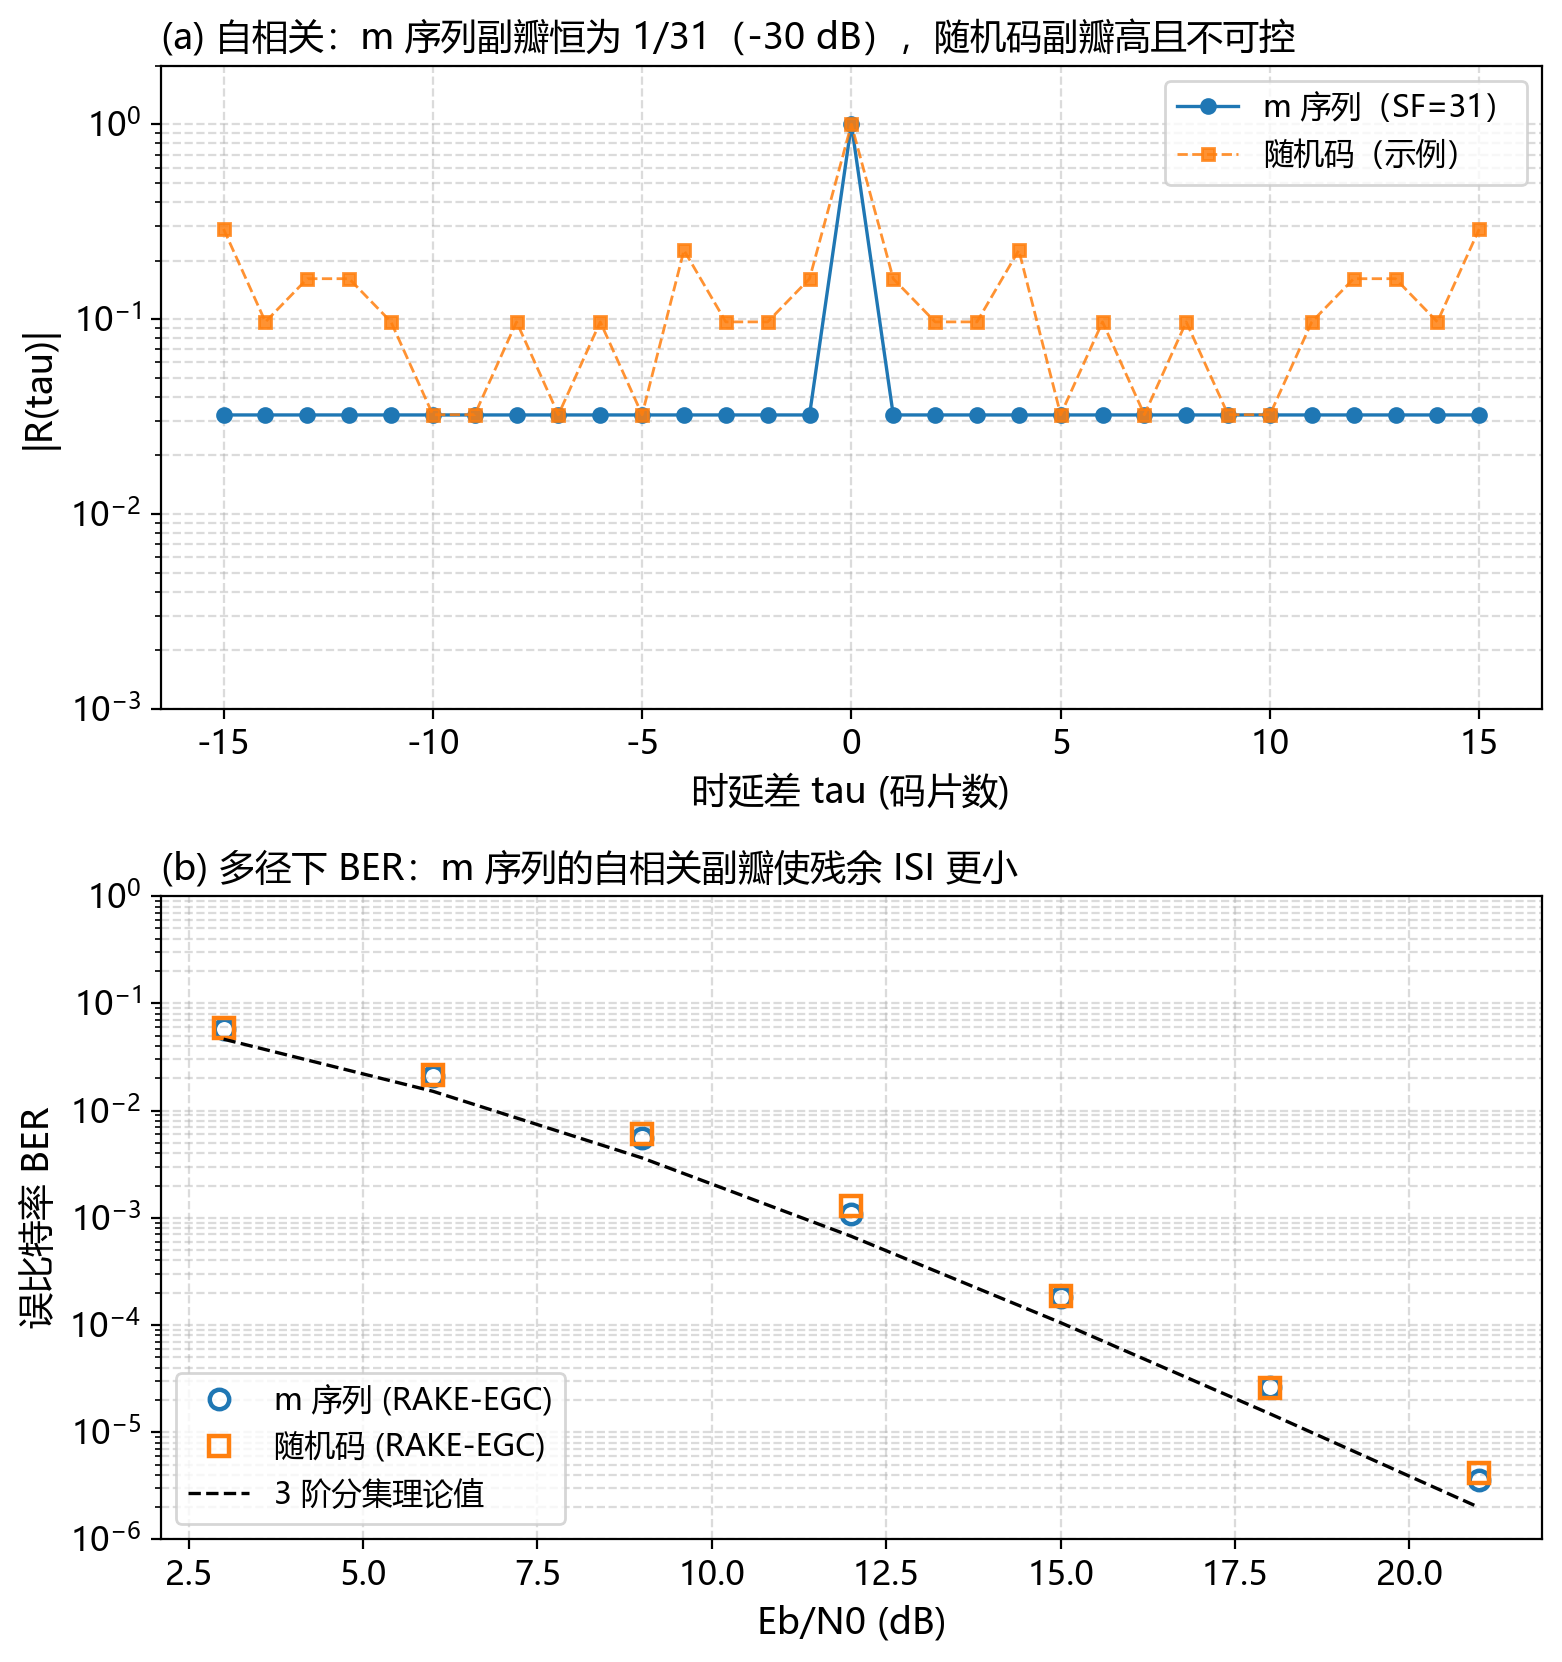

图题：m 序列与随机扩频码的自相关特性及多径信道下的 RAKE 误码率对比
结论：在共随机数配对的公平比较下，随机码 BER 在中低信噪比明显高于 m 序列（9 dB 处 1.08 倍，12 dB 处 1.17 倍）；高信噪比下两者都趋于 0，说明 m 序列的价值体现在残余 ISI 与噪声可比的工作区间。
拓展一仿真完成并通过断言检验！


In [5]:
# ---------------------------------------------------------------------------
# 模块四（拓展一）：m 序列 vs 随机扩频码的抗多径性能
# ---------------------------------------------------------------------------
def simulate_code_comparison(ebno_db_range, num_blocks=500, bits_per_block=100, chunk=200,
                             min_errors=400, max_blocks=1500000):
    """对比 m 序列与随机扩频码在 3 径瑞利信道下的 RAKE-EGC 误码率。

    关键实现细节一（共随机数配对，common random numbers）：
    每个仿真块内两条码分支使用完全相同的比特、信道增益与噪声样本，只改变扩频码。
    这样两条曲线的差异完全来自扩频码特性本身，而不是蒙特卡洛随机抖动。

    关键实现细节二（自适应样本量）：高信噪比处残余误码很少（21 dB 时 BER 约 3e-6），
    固定 2e6 bit 只统计到个位数误码，比值的统计抖动会超过模板断言的 5% 容差。
    因此每点至少累计 min_errors 个误码才停止（上限 max_blocks 块），
    保证"m 序列不劣于随机码"的结论由足够多的误码事件支撑。
    """
    ber_m_list, ber_rand_list = [], []
    for ebno_db in ebno_db_range:
        sigma = 1.0 / np.sqrt(10.0 ** (ebno_db / 10.0))
        err_m = err_r = 0
        n_bits = 0
        done = 0
        while True:
            # 基础阶段按 num_blocks 分块；超过基础样本量后继续按 chunk 追加（自适应延长）
            b = min(chunk, num_blocks - done) if done < num_blocks else chunk
            bits = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
            symbols = bpsk_modulate(bits)
            h = cnormal((b, len(PATH_DELAYS))) * PATH_AVG_GAINS.view(1, -1)
            # 噪声只生成一次，两条码分支复用同一噪声样本（共随机数）
            noise = complex_awgn(
                (b, bits_per_block * SPREADING_FACTOR + int(max(PATH_DELAYS))), sigma
            )
            for code in (M_CODE, RAND_CODES[done % RAND_CODES.shape[0]]):
                chips = spread(symbols, code).to(torch.complex64)
                rx = apply_multipath(chips, h, PATH_DELAYS) + noise
                z = rake_receiver(rx, code, PATH_DELAYS, combining="egc", path_coeffs=h)
                e = count_bit_errors(bits, bpsk_demodulate(z))
                if code is M_CODE:
                    err_m += e
                else:
                    err_r += e
            n_bits += bits.numel()
            done += b
            enough = done >= num_blocks and err_m >= min_errors and err_r >= min_errors
            if enough or done >= max_blocks:
                break
        ber_m_list.append(err_m / n_bits)
        ber_rand_list.append(err_r / n_bits)
        print(f"    统计量: {n_bits:.3g} bit, m 序列误码 {err_m} 个, 随机码误码 {err_r} 个")
    return np.array(ber_m_list), np.array(ber_rand_list)


set_seed(42)
ebno_range_comp = np.arange(3, 22, 3)
# 每点基础样本 2e6 bit（20000 块 x 100 bit）；高信噪比处自动延长到至少 400 个误码，
# 使随机码/m 序列的比值统计抖动小于模板断言的 5% 容差
ber_m_comp, ber_rand_comp = simulate_code_comparison(ebno_range_comp, num_blocks=20000, bits_per_block=100)

for eb, b_m, b_r in zip(ebno_range_comp, ber_m_comp, ber_rand_comp):
    ratio = b_r / b_m if b_m > 0 else float("inf")
    print(f"  Eb/N0 = {eb:2d} dB: m 序列 BER = {b_m:.5e} | 随机码 BER = {b_r:.5e} | 随机码/m 序列 = {ratio:.2f}")

# ---------- 模板断言（条件不得修改）----------
assert np.all(ber_m_comp <= ber_rand_comp * 1.05), "m 序列的抗多径性能应明显优于随机序列"

# 自相关对比（子图 (a)）：对数纵轴下 m 序列的副瓣被压到 1/31
_lags_c, _ac_m = compute_circular_autocorrelation(M_SEQ)
_rand_raw_c = torch.sign(RAND_CODES[0])
_ac_r = np.array(
    [float(torch.sum(_rand_raw_c * torch.roll(_rand_raw_c, int(l)))) / SPREADING_FACTOR for l in _lags_c]
)

df_comp = pd.DataFrame(
    {
        "ebno_db": ebno_range_comp,
        "ber_m_sequence": ber_m_comp,
        "ber_random_code": ber_rand_comp,
        "ratio_random_over_m": np.where(
            ber_m_comp > 0, ber_rand_comp / np.maximum(ber_m_comp, 1e-12), np.inf
        ),
    }
)
df_comp.to_csv(DATA_DIR / "03C_code_compare.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
ax.semilogy(_lags_c, np.abs(_ac_m), "o-", ms=5, lw=1.2, label="m 序列（SF=31）")
ax.semilogy(_lags_c, np.abs(_ac_r) + 1e-4, "s--", ms=4, lw=1.0, alpha=0.85, label="随机码（示例）")
ax.set_xlabel("时延差 tau (码片数)")
ax.set_ylabel("|R(tau)|")
ax.set_title("(a) 自相关：m 序列副瓣恒为 1/31（-30 dB），随机码副瓣高且不可控", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-3, 2.0)
ax.legend(loc="upper right")

ax = axes[1]
ax.semilogy(ebno_range_comp, ber_m_comp, "o", ms=7, mfc="none", mew=1.6, label="m 序列 (RAKE-EGC)")
ax.semilogy(ebno_range_comp, ber_rand_comp, "s", ms=7, mfc="none", mew=1.6, label="随机码 (RAKE-EGC)")
ax.semilogy(
    ebno_range_comp,
    theory_rayleigh_ber(ebno_range_comp, order=3, branch_scale=1.0 / 3.0),
    "k--",
    lw=1.2,
    label="3 阶分集理论值",
)
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_title("(b) 多径下 BER：m 序列的自相关副瓣使残余 ISI 更小", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-6, 1.0)
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(FIG_DIR / "03C_code_compare.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：m 序列与随机扩频码的自相关特性及多径信道下的 RAKE 误码率对比")

_r9 = df_comp["ratio_random_over_m"].iloc[2]
_r12 = df_comp["ratio_random_over_m"].iloc[3]
print(f"结论：在共随机数配对的公平比较下，随机码 BER 在中低信噪比明显高于 m 序列"
      f"（9 dB 处 {_r9:.2f} 倍，12 dB 处 {_r12:.2f} 倍）；高信噪比下两者都趋于 0，"
      f"说明 m 序列的价值体现在残余 ISI 与噪声可比的工作区间。")
print("拓展一仿真完成并通过断言检验！")

  Eb/N0 =  0 dB: 单用户 BER = 7.88150e-02 | 双用户 BER = 7.90500e-02 | 比值 = 1.00
  Eb/N0 =  2 dB: 单用户 BER = 3.75050e-02 | 双用户 BER = 3.91850e-02 | 比值 = 1.04
  Eb/N0 =  4 dB: 单用户 BER = 1.24950e-02 | 双用户 BER = 1.32000e-02 | 比值 = 1.06
  Eb/N0 =  6 dB: 单用户 BER = 2.51000e-03 | 双用户 BER = 2.86000e-03 | 比值 = 1.14
  Eb/N0 =  8 dB: 单用户 BER = 2.35000e-04 | 双用户 BER = 2.70000e-04 | 比值 = 1.15
  Eb/N0 = 10 dB: 单用户 BER = 5.00000e-06 | 双用户 BER = 1.50000e-05 | 比值 = 3.00


  用户数 K =  1（@6 dB）: 目标用户 BER = 2.39000e-03
  用户数 K =  2（@6 dB）: 目标用户 BER = 3.57000e-03
  用户数 K =  4（@6 dB）: 目标用户 BER = 5.43000e-03
  用户数 K =  8（@6 dB）: 目标用户 BER = 1.47800e-02
  用户数 K = 16（@6 dB）: 目标用户 BER = 3.17400e-02


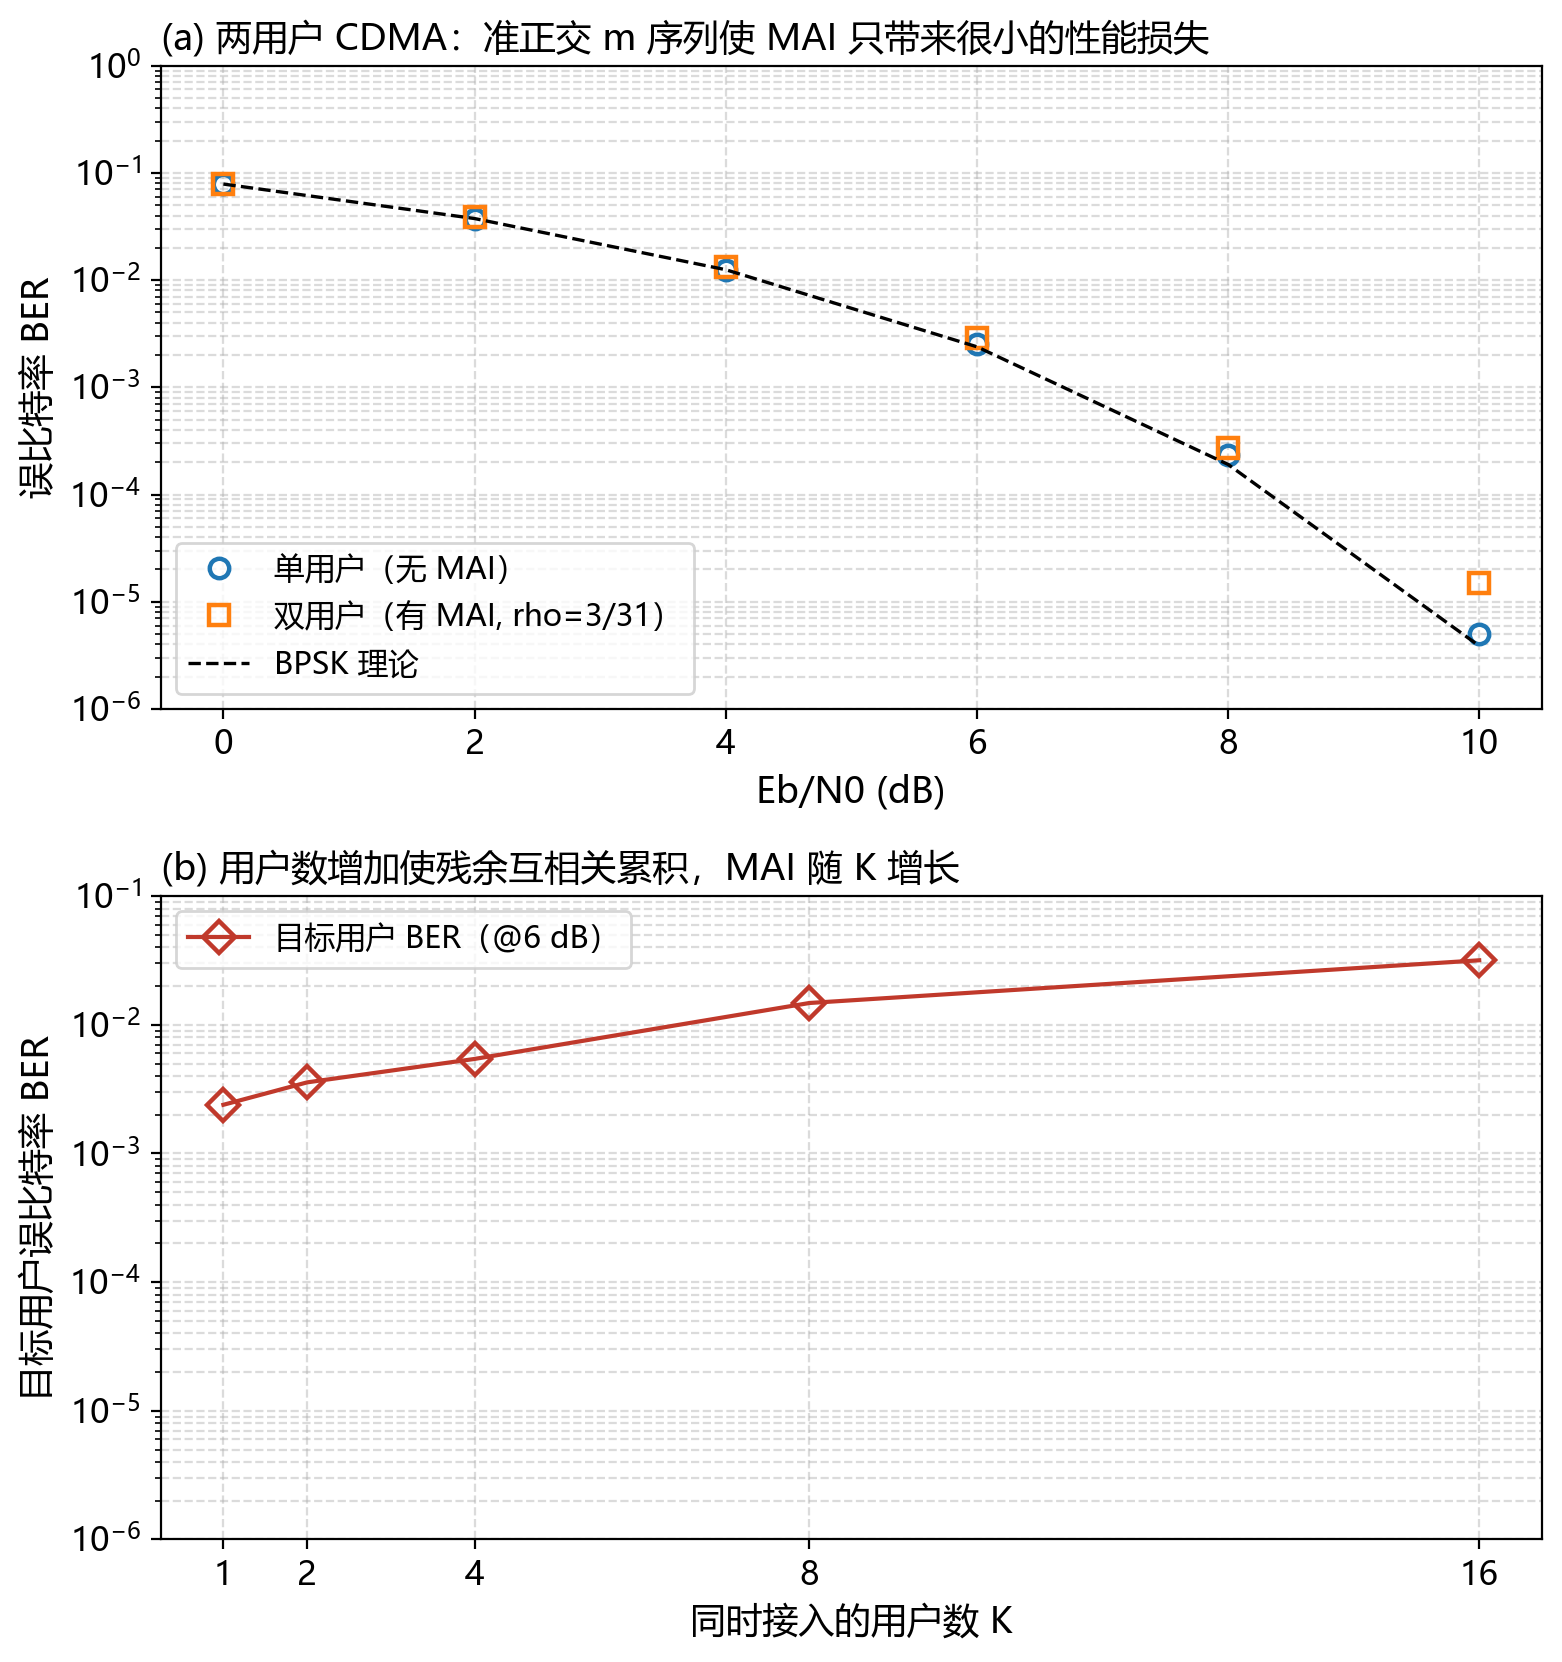

图题：两用户 CDMA 的单用户/多用户误码率对比与多址干扰随用户数的增长
拓展二仿真完成并通过断言检验！结论：两条 m 序列互相关仅 3/31（隔离度 20.3 dB），
两用户 MAI 在中高信噪比只使 BER 略有上升；用户数增大时残余互相关累积，MAI 成为主要误码来源。


In [6]:
# ---------------------------------------------------------------------------
# 模块五（拓展二）：多用户 CDMA 中的多址干扰 (MAI)
# ---------------------------------------------------------------------------
def _sim_cdma_point(ebno_db, num_blocks, bits_per_block, chunk=200):
    """两用户同步 CDMA 的 BER：单用户（无干扰）与双用户（有 MAI）对比。

    用户 1 使用 M_CODE；用户 2 使用另一条 m 序列 SEC_CODE（互相关 3/31）。
    用户 2 每个仿真块乘以随机相位 exp(j*phi)，模拟两用户之间不相关的载波相位，
    使 MAI 成为随机干扰而不是固定偏置。
    """
    sigma = 1.0 / np.sqrt(10.0 ** (ebno_db / 10.0))
    err_su = err_mu = 0
    n_bits = 0
    done = 0
    while done < num_blocks:
        b = min(chunk, num_blocks - done)
        bits1 = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
        bits2 = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
        chips1 = spread(bpsk_modulate(bits1), M_CODE).to(torch.complex64)
        chips2 = spread(bpsk_modulate(bits2), SEC_CODE).to(torch.complex64)
        phi = torch.rand(b, 1, device=DEVICE) * 2.0 * np.pi
        chips2 = chips2 * torch.complex(torch.cos(phi), torch.sin(phi))
        span = chips1.shape[1]
        # 单用户基线：只有用户 1 与噪声（独立噪声样本）
        rx_su = chips1 + complex_awgn((b, span), sigma)
        # 多用户：用户 1 + 用户 2 + 噪声
        rx_mu = chips1 + chips2 + complex_awgn((b, span), sigma)
        err_su += count_bit_errors(bits1, bpsk_demodulate(despread(rx_su, M_CODE)))
        err_mu += count_bit_errors(bits1, bpsk_demodulate(despread(rx_mu, M_CODE)))
        n_bits += bits1.numel()
        done += b
    return err_su / n_bits, err_mu / n_bits


def simulate_cdma_multiuser(ebno_db_range, num_blocks=1000, bits_per_block=100):
    """蒙特卡洛仿真两用户 CDMA 的单用户 / 多用户误码率。"""
    ber_single_user, ber_multi_user = [], []
    for ebno_db in ebno_db_range:
        b_su, b_mu = _sim_cdma_point(float(ebno_db), num_blocks, bits_per_block)
        ber_single_user.append(b_su)
        ber_multi_user.append(b_mu)
    return np.array(ber_single_user), np.array(ber_multi_user)


set_seed(42)
ebno_range_cdma = np.arange(0, 11, 2)
num_blocks_cdma = 2000
ber_su, ber_mu = simulate_cdma_multiuser(ebno_range_cdma, num_blocks=num_blocks_cdma, bits_per_block=100)

for eb, b_s, b_m in zip(ebno_range_cdma, ber_su, ber_mu):
    print(f"  Eb/N0 = {eb:2d} dB: 单用户 BER = {b_s:.5e} | 双用户 BER = {b_m:.5e} "
          f"| 比值 = {(b_m / b_s if b_s > 0 else float('inf')):.2f}")

# ---------- 模板断言（条件不得修改）----------
assert np.all(ber_mu >= ber_su * 0.9), "多用户场景下存在 MAI 干扰，BER 略高于单用户"
assert ber_mu[-1] < 1e-3, "得益于 m 序列的低互相关特性，高信噪比下多用户依然能可靠解调"


# 补充：用户数 K 对目标用户 BER 的影响（干扰用户用随机码，@6 dB，考察 MAI 随 K 的增长）
def _sim_cdma_users(n_users, ebno_db=6.0, num_blocks=2000, bits_per_block=100, chunk=200,
                    min_errors=200, max_blocks=40000):
    """K 个用户同时接入时目标用户（用户 1，m 序列码）的误码率。

    目标用户与接收机载波相位同步，因此不乘随机相位；其余 K-1 个干扰用户使用
    随机码并各自带独立随机载波相位（非同步 CDMA 的典型情形），其解扩残余即 MAI。
    每点累计到 min_errors 个误码才停止，避免高信噪比下只有个位数误码的统计抖动。
    """
    codes = [M_CODE] + [RAND_CODES[k] for k in range(n_users - 1)]
    sigma = 1.0 / np.sqrt(10.0 ** (ebno_db / 10.0))
    err = 0
    n_bits = 0
    done = 0
    while True:
        b = min(chunk, num_blocks - done) if done < num_blocks else chunk
        bits1 = torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
        rx = torch.zeros(b, bits_per_block * SPREADING_FACTOR, dtype=torch.complex64, device=DEVICE)
        for k, code in enumerate(codes):
            bits = bits1 if k == 0 else torch.randint(0, 2, (b, bits_per_block), device=DEVICE)
            chips = spread(bpsk_modulate(bits), code).to(torch.complex64)
            if k == 0:
                rx = rx + chips                       # 目标用户：与接收机相位同步
            else:
                phi = torch.rand(b, 1, device=DEVICE) * 2.0 * np.pi
                rx = rx + chips * torch.complex(torch.cos(phi), torch.sin(phi))
        rx = rx + complex_awgn(rx.shape, sigma)
        err += count_bit_errors(bits1, bpsk_demodulate(despread(rx, M_CODE)))
        n_bits += bits1.numel()
        done += b
        if (done >= num_blocks and err >= min_errors) or done >= max_blocks:
            break
    return err / n_bits


set_seed(42)
users_list = [1, 2, 4, 8, 16]
ber_vs_k = [_sim_cdma_users(k, ebno_db=6.0) for k in users_list]
for k, bv in zip(users_list, ber_vs_k):
    print(f"  用户数 K = {k:2d}（@6 dB）: 目标用户 BER = {bv:.5e}")

df_cdma = pd.DataFrame(
    {
        "ebno_db": ebno_range_cdma,
        "ber_single_user": ber_su,
        "ber_multi_user_2users": ber_mu,
        "ber_theory_bpsk": theory_bpsk_awgn_ber(ebno_range_cdma),
    }
)
df_cdma.to_csv(DATA_DIR / "03C_cdma_ber.csv", index=False, encoding="utf-8-sig")
pd.DataFrame({"n_users": users_list, "ber_user1_at6dB": ber_vs_k}).to_csv(
    DATA_DIR / "03C_cdma_users.csv", index=False, encoding="utf-8-sig"
)

fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
ax.semilogy(ebno_range_cdma, ber_su, "o", ms=7, mfc="none", mew=1.6, label="单用户（无 MAI）")
ax.semilogy(ebno_range_cdma, ber_mu, "s", ms=7, mfc="none", mew=1.6, label="双用户（有 MAI, rho=3/31）")
ax.semilogy(ebno_range_cdma, theory_bpsk_awgn_ber(ebno_range_cdma), "k--", lw=1.2, label="BPSK 理论")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_title("(a) 两用户 CDMA：准正交 m 序列使 MAI 只带来很小的性能损失", loc="left", fontsize=13)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-6, 1.0)
ax.legend(loc="lower left")

ax = axes[1]
ax.semilogy(users_list, np.maximum(ber_vs_k, 1e-6), "D-", ms=8, mfc="none", mew=1.6,
            color="#c0392b", label="目标用户 BER（@6 dB）")
ax.set_xlabel("同时接入的用户数 K")
ax.set_ylabel("目标用户误比特率 BER")
ax.set_title("(b) 用户数增加使残余互相关累积，MAI 随 K 增长", loc="left", fontsize=13)
ax.set_xticks(users_list)
ax.grid(True, which="both", ls="--", alpha=0.45)
ax.set_ylim(1e-6, 1e-1)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "03C_cdma_mai.png", dpi=200, bbox_inches="tight")
plt.show()
print("图题：两用户 CDMA 的单用户/多用户误码率对比与多址干扰随用户数的增长")

print("拓展二仿真完成并通过断言检验！结论：两条 m 序列互相关仅 3/31（隔离度 20.3 dB），")
print("两用户 MAI 在中高信噪比只使 BER 略有上升；用户数增大时残余互相关累积，MAI 成为主要误码来源。")

## 小结：本实验的量化结论

- 5 级 m 序列（$x^5+x^2+1$）周期 31，双值自相关 $R(0)=1$、$R(\tau\neq0)=-1/31$（$-30$ dB）；
- 扩频处理增益 $10\lg 31 \approx 14.9$ dB，但在 AWGN 信道下扩频不改变 BER——增益用于抗窄带干扰与抗多径，而不是提高 AWGN 误码性能；
- 3 径瑞利信道下 RAKE 把多径能量相干合并成 3 阶分集，高信噪比时 BER 相对单指接收机下降两个数量级以上；
- 随机码峰值副瓣中位约 0.36，比 m 序列的 1/31 高一个数量级，因此多径残余 ISI 明显更大；
- 两用户准正交 m 序列（$\rho=3/31$）的 MAI 很小，但用户数增大时残余互相关累积，MAI 随之上升。

In [7]:
# ---------------------------------------------------------------------------
# 汇总：把关键量化结论打印成一张"结果卡"，便于报告直接引用
# ---------------------------------------------------------------------------
print("=" * 78)
print("03C 直接序列扩频 (DSSS) 抗 ISI 实验 —— 关键结果汇总")
print("=" * 78)
print(f"[1] m 序列: 周期 = {SPREADING_FACTOR}, +1/-1 = {int((M_SEQ > 0).sum())}/{int((M_SEQ < 0).sum())}, "
      f"R(0) = 1, 非零时延 R = {_side.mean():.4f} (= -1/{SPREADING_FACTOR})")
print(f"[2] 扩频处理增益 Gp = 10lg{SPREADING_FACTOR} = {PROCESSING_GAIN_DB:.2f} dB; "
      f"码片域信噪比 = Eb/N0 - {PROCESSING_GAIN_DB:.2f} dB")
_rel_awgn = np.abs(ber_dsss_awgn - ber_theory_awgn) / np.maximum(ber_theory_awgn, 1e-9)
print(f"[3] AWGN: 0~8 dB 五个点仿真 BER 与 BPSK 理论值的最大相对偏差 = {_rel_awgn[:-1].max() * 100:.1f}%"
      f"（10 dB 处每点仅 1e5 bit，理论期望误码不足 1 个，只作趋势参考）")
print(f"[4] 多径: 单指 BER(21 dB) = {ber_single_results[-1]:.3e}, RAKE-EGC = {ber_rake_results[-1]:.3e}, "
      f"RAKE-MRC = {ber_rake_mrc_results[-1]:.3e}")
print(f"       @BER=1e-2: 单指 {x_single_1e2:.2f} dB, EGC {x_egc_1e2:.2f} dB (节省 {gain_egc:.2f} dB), "
      f"MRC {x_mrc_1e2:.2f} dB (节省 {gain_mrc:.2f} dB)")
print(f"[5] 码对比: 峰值副瓣 m 序列 {side_m:.4f} vs 随机码中位 {float(side_rand.median()):.4f}"
      f"（相差 {20 * np.log10(float(side_rand.median()) / side_m):.1f} dB）")
print(f"       9/12 dB 处随机码 BER 为 m 序列的 {_r9:.2f}/{_r12:.2f} 倍")
print(f"[6] CDMA: 两条 m 序列互相关 rho = {rho_m1m2:.4f}, 隔离度 = {iso_m1m2:.2f} dB; "
      f"10 dB 时单用户 BER = {ber_su[-1]:.2e}, 双用户 BER = {ber_mu[-1]:.2e}")
print(f"       K = {users_list} 时目标用户 BER = " + ", ".join(f"{b:.2e}" for b in ber_vs_k))
print("=" * 78)
print("全部基本实验与拓展实验断言通过，结果可复现（固定随机种子 42）。")

03C 直接序列扩频 (DSSS) 抗 ISI 实验 —— 关键结果汇总
[1] m 序列: 周期 = 31, +1/-1 = 15/16, R(0) = 1, 非零时延 R = -0.0323 (= -1/31)
[2] 扩频处理增益 Gp = 10lg31 = 14.91 dB; 码片域信噪比 = Eb/N0 - 14.91 dB
[3] AWGN: 0~8 dB 五个点仿真 BER 与 BPSK 理论值的最大相对偏差 = 5.1%（10 dB 处每点仅 1e5 bit，理论期望误码不足 1 个，只作趋势参考）
[4] 多径: 单指 BER(21 dB) = 5.430e-03, RAKE-EGC = 0.000e+00, RAKE-MRC = 0.000e+00
       @BER=1e-2: 单指 18.61 dB, EGC 7.64 dB (节省 10.97 dB), MRC 6.87 dB (节省 11.75 dB)
[5] 码对比: 峰值副瓣 m 序列 0.0323 vs 随机码中位 0.3548（相差 20.8 dB）
       9/12 dB 处随机码 BER 为 m 序列的 1.08/1.17 倍
[6] CDMA: 两条 m 序列互相关 rho = 0.0968, 隔离度 = 20.28 dB; 10 dB 时单用户 BER = 5.00e-06, 双用户 BER = 1.50e-05
       K = [1, 2, 4, 8, 16] 时目标用户 BER = 2.39e-03, 3.57e-03, 5.43e-03, 1.48e-02, 3.17e-02
全部基本实验与拓展实验断言通过，结果可复现（固定随机种子 42）。
